# Laboratorio 4 - Segmentación de imágenes con técnicas de agrupación

Integrantes:
- Juan Felipe Saenz - 202311148
- Tomas Aguilera - 202321962

En este laboratorio trabajamos el caso de DermAlpes, una empresa de telemedicina que quiere una herramienta que delimite automáticamente la lesión en fotos de dermatoscopio, para que el dermatólogo pueda medirla y concentrarse en la zona relevante. Como DermAlpes no tiene imágenes etiquetadas propias, la idea es probar si se puede segmentar la lesión **sin entrenar un modelo supervisado**, agrupando los píxeles con K-medias según su color y su posición. Las máscaras de referencia hechas por dermatólogos no se usan para agrupar, solo para medir qué tan bien funciona el método, dónde falla y por qué.

El notebook sigue las actividades del enunciado (1 a 6), después vienen las respuestas del análisis de resultados, la sección de uso de IA generativa (que incluye la actividad de verificación) y al final los bonos.

**Fuente de los datos.** Usamos 20 imágenes del conjunto de entrenamiento de la tarea 1 (segmentación de lesiones) del reto ISIC 2016, con sus máscaras de referencia: https://challenge.isic-archive.com/landing/2016/37/

Gutman, D., Codella, N. C. F., Celebi, E., Helba, B., Marchetti, M., Mishra, N. y Halpern, A. (2016). *Skin Lesion Analysis toward Melanoma Detection: A Challenge at the International Symposium on Biomedical Imaging (ISBI) 2016, hosted by the International Skin Imaging Collaboration (ISIC)*. arXiv:1605.01397.

De las 900 imágenes del conjunto copiamos a la carpeta `data/` solo las 20 que pide el enunciado: las fotos en `data/imagenes/` y sus máscaras (`_Segmentation.png`) en `data/mascaras/`.

## Importamos librerías

In [1]:
import os
# En Windows joblib intenta contar los nucleos fisicos con un comando que ya no existe
# y llena la salida con un traceback, con esto se evita
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(max(1, os.cpu_count() - 1)))

import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage as ndi
from skimage.segmentation import find_boundaries

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans, MeanShift, estimate_bandwidth
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, f1_score, v_measure_score,
                             precision_score, recall_score)

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

SEMILLA = 42            # semilla para K-medias y para la muestra de la silueta
TAMANO_MUESTRA = 3000   # pixeles usados para calcular la silueta
VALORES_K = list(range(2, 9))
LADO_MAX = 256          # tamano del lado mas largo despues de reducir la imagen

AJUSTE = ["0000085", "0000086", "0000089", "0000094", "0000108",
          "0000114", "0000116", "0000122", "0000133", "0000137",
          "0000150", "0000153", "0000156", "0000157", "0000112"]
PRUEBA = ["0000087", "0000105", "0000110", "0000123", "0000128"]

## Cargamos las imágenes de ajuste

Para respetar el protocolo, en esta parte solo cargamos las 15 imágenes de ajuste y sus máscaras. Las 5 imágenes de prueba y sus máscaras se cargan recién en la actividad 5, cuando la configuración ya está escogida.

In [2]:
def cargar_imagen(id_img):
    return np.asarray(Image.open(f"data/imagenes/ISIC_{id_img}.jpg").convert("RGB"))


def cargar_mascara(id_img):
    return np.asarray(Image.open(f"data/mascaras/ISIC_{id_img}_Segmentation.png"))


imagenes_ajuste = {i: cargar_imagen(i) for i in AJUSTE}
mascaras_ajuste = {i: cargar_mascara(i) for i in AJUSTE}

pd.DataFrame([{
    "Imagen": f"ISIC_{i}",
    "Alto": imagenes_ajuste[i].shape[0],
    "Ancho": imagenes_ajuste[i].shape[1],
    "Valores en la máscara": np.unique(mascaras_ajuste[i]).tolist(),
    "% de la imagen que es lesión": round((mascaras_ajuste[i] > 0).mean() * 100, 1),
} for i in AJUSTE])

,Imagen,Alto,Ancho,Valores en la máscara,% de la imagen que es lesión
0,ISIC_0000085,1536,2048,"[0, 255]",12.7
1,ISIC_0000086,1944,2592,"[0, 255]",23.4
2,ISIC_0000089,1536,2048,"[0, 255]",12.1
3,ISIC_0000094,1536,2048,"[0, 255]",5.9
4,ISIC_0000108,1536,2048,"[0, 255]",18.5
5,ISIC_0000114,1536,2048,"[0, 255]",3.1
6,ISIC_0000116,1536,2048,"[0, 255]",36.1
7,ISIC_0000122,1536,2048,"[0, 255]",39.0
8,ISIC_0000133,1536,2048,"[0, 255]",14.2
9,ISIC_0000137,1536,2048,"[0, 255]",24.5


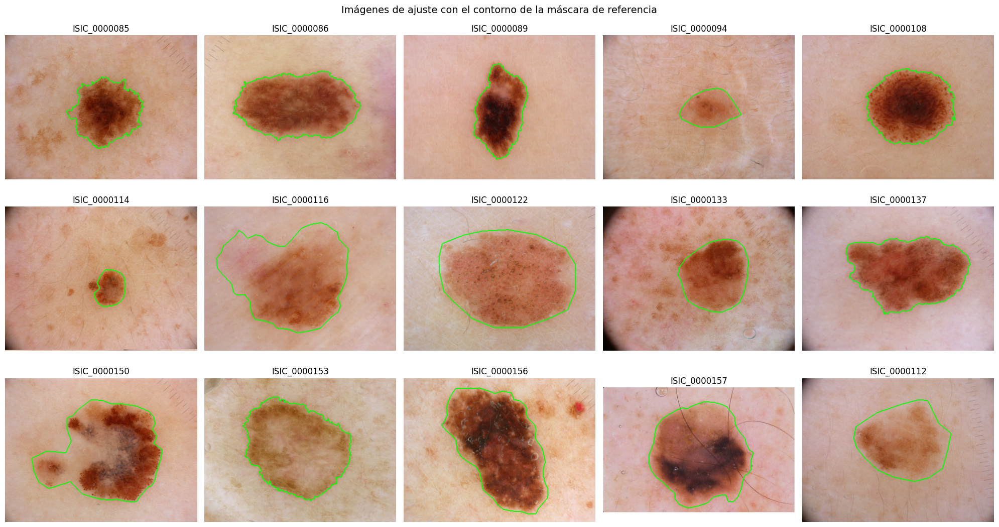

In [3]:
# Imagenes de ajuste con el contorno de la mascara de referencia en verde
def dibujar_contorno(img, mascara, color=(0, 255, 0)):
    salida = img.copy()
    salida[find_boundaries(mascara > 0, mode="thick")] = color
    return salida


fig, axes = plt.subplots(3, 5, figsize=(20, 11))
for ax, i in zip(axes.ravel(), AJUSTE):
    img = Image.fromarray(imagenes_ajuste[i])
    img.thumbnail((400, 400))
    m = np.asarray(Image.fromarray(mascaras_ajuste[i]).resize(img.size, Image.NEAREST))
    ax.imshow(dibujar_contorno(np.asarray(img), m))
    ax.set_title(f"ISIC_{i}")
    ax.axis("off")
plt.suptitle("Imágenes de ajuste con el contorno de la máscara de referencia", fontsize=14)
plt.tight_layout()
plt.show()

Las 15 imágenes de ajuste tienen hasta 2592 × 1944 píxeles (la única más pequeña es ISIC_0000157, de 963 × 629) y sus máscaras vienen con valores 0 y 255, como dice el enunciado. La lesión ocupa desde el 3.1% de la imagen (ISIC_0000114) hasta el 39% (ISIC_0000122). Mirando las fotos ya se ven los casos que le pueden complicar la vida al método:

- **Esquinas oscuras** por el lente del dermatoscopio, en ISIC_0000133, ISIC_0000112 e ISIC_0000114. Como también son oscuras, un criterio basado solo en el color las puede confundir con la lesión.
- **Lesiones pálidas o con poco contraste** con la piel, como ISIC_0000094, ISIC_0000116, ISIC_0000122 e ISIC_0000112.
- **Lesiones con zonas de distinto color**, como ISIC_0000150, que tiene un centro grisáceo y una mancha separada a la izquierda.
- **Vellos y reglas de medición**, por ejemplo los vellos que cruzan ISIC_0000157 y la regla en la esquina superior derecha de varias imágenes.

También se ve que la lesión casi siempre está cerca del centro, lo que sugiere que la posición puede ayudar a separarla de las esquinas.

## Actividad 1 - Pipeline de preparación y representación

Armamos un pipeline de scikit-learn con dos transformadores propios:

1. `Redimensionar`: reduce la imagen para que su lado más largo mida `LADO_MAX` = 256 píxeles, conservando la proporción. Las imágenes originales tienen hasta 2592 × 1944 píxeles (unos 5 millones de píxeles), y agrupar eso con K-medias para 7 valores de K, 10 combinaciones y 15 imágenes sería muy lento. A 256 píxeles quedan unos 49 mil píxeles por imagen, que todavía muestran bien la forma de la lesión. Para la imagen usamos interpolación bilineal, que además suaviza un poco el ruido.
2. `PixelesColorPosicion`: convierte la imagen en una matriz con un píxel por fila y las columnas [β·R, β·G, β·B, λ·x, λ·y]. El color se divide por 255 y las coordenadas por el ancho y el alto menos uno, entonces todo queda en [0, 1]. β y λ son hiperparámetros del transformador, así que se pueden cambiar con `set_params` sin tocar la implementación.

Las máscaras se preparan aparte con `preparar_mascara`: pasan de 0/255 a 0/1 y se reducen al mismo tamaño de la imagen con vecino más cercano, para que sigan siendo binarias.

In [4]:
class Redimensionar(BaseEstimator, TransformerMixin):
    # Reduce la imagen para que el lado mas largo mida lado_max pixeles, sin deformarla
    def __init__(self, lado_max=256):
        self.lado_max = lado_max

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        img = Image.fromarray(X)
        escala = self.lado_max / max(img.size)
        nuevo = (round(img.size[0] * escala), round(img.size[1] * escala))
        return np.asarray(img.resize(nuevo, Image.BILINEAR))


class PixelesColorPosicion(BaseEstimator, TransformerMixin):
    # Pasa de una imagen (alto, ancho, 3) a una matriz con un pixel por fila y las
    # columnas [beta*R, beta*G, beta*B, lam*x, lam*y], con color y posicion en [0, 1]
    def __init__(self, beta=1.0, lam=0.0):
        self.beta = beta
        self.lam = lam

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        alto, ancho, _ = X.shape
        color = X.reshape(-1, 3).astype(float) / 255.0
        filas, columnas = np.mgrid[0:alto, 0:ancho]
        posicion = np.column_stack([columnas.ravel() / (ancho - 1), filas.ravel() / (alto - 1)])
        return np.hstack([self.beta * color, self.lam * posicion])


def crear_pipeline(beta=1.0, lam=0.0, lado_max=LADO_MAX):
    return Pipeline([
        ("redimension", Redimensionar(lado_max=lado_max)),
        ("representacion", PixelesColorPosicion(beta=beta, lam=lam)),
    ])


def preparar_mascara(mascara, forma):
    # 0/255 -> 0/1 y mismo tamano que la imagen reducida, con vecino mas cercano
    alto, ancho = forma
    reducida = Image.fromarray(mascara).resize((ancho, alto), Image.NEAREST)
    return (np.asarray(reducida) > 127).astype(np.uint8)

In [5]:
# Probamos el pipeline con una imagen y revisamos que beta y lam hagan lo que deben
pipe = crear_pipeline(beta=1, lam=0.5)
img = imagenes_ajuste["0000085"]
X = pipe.fit_transform(img)
reducida = pipe.named_steps["redimension"].transform(img)
columnas = ["β·R", "β·G", "β·B", "λ·x", "λ·y"]

print("Imagen original:", img.shape, "-> reducida:", reducida.shape)
print("Matriz de pixeles:", X.shape, "(un pixel por fila)")
print("Mínimos:", X.min(axis=0).round(3), " Máximos:", X.max(axis=0).round(3))
display(pd.DataFrame(X[:3], columns=columnas).round(3))

pipe.set_params(representacion__beta=0, representacion__lam=1)
print("β = 0, λ = 1 (solo posición):")
display(pd.DataFrame(pipe.fit_transform(img)[:3], columns=columnas).round(3))

pipe.set_params(representacion__beta=1, representacion__lam=0)
print("β = 1, λ = 0 (solo color):")
display(pd.DataFrame(pipe.fit_transform(img)[:3], columns=columnas).round(3))

mascara = preparar_mascara(mascaras_ajuste["0000085"], reducida.shape[:2])
print("Máscara preparada:", mascara.shape, "valores:", np.unique(mascara), "% lesión:", round(mascara.mean() * 100, 1))

Imagen original: (1536, 2048, 3) -> reducida: (192, 256, 3)
Matriz de pixeles: (49152, 5) (un pixel por fila)
Mínimos: [0.227 0.031 0.008 0.    0.   ]  Máximos: [0.843 0.714 0.714 0.5   0.5  ]


,β·R,β·G,β·B,λ·x,λ·y
0,0.525,0.396,0.373,0.000,0.0
1,0.537,0.408,0.373,0.002,0.0
2,0.553,0.424,0.369,0.004,0.0


β = 0, λ = 1 (solo posición):


,β·R,β·G,β·B,λ·x,λ·y
0,0.0,0.0,0.0,0.000,0.0
1,0.0,0.0,0.0,0.004,0.0
2,0.0,0.0,0.0,0.008,0.0


β = 1, λ = 0 (solo color):


,β·R,β·G,β·B,λ·x,λ·y
0,0.525,0.396,0.373,0.0,0.0
1,0.537,0.408,0.373,0.0,0.0
2,0.553,0.424,0.369,0.0,0.0


Máscara preparada: (192, 256) valores: [0 1] % lesión: 12.7


El pipeline funciona como se espera: la imagen de 1536 × 2048 queda en 192 × 256, la matriz tiene un píxel por fila y las cinco columnas quedan en [0, 1] (multiplicadas por β o λ). Con β = 0 las tres columnas de color quedan en cero y con λ = 0 las de posición, entonces la misma implementación sirve para usar solo color, solo posición o una mezcla. La máscara reducida conserva los valores 0 y 1 y casi el mismo porcentaje de lesión que la original (12.7%).

## Actividad 2 - Agrupación y selección de K

Probamos 10 combinaciones de β y λ. Como lo que importa es la razón λ/β (multiplicar las dos por la misma constante no cambia los grupos), dejamos β = 1 y movemos λ, y agregamos una combinación con solo posición (β = 0, λ = 1). Las razones van de 0 (solo color) a infinito (solo posición), con más puntos en valores bajos. La razón es que el color de la lesión y el de la piel se diferencian en unas pocas décimas por canal, mientras que la posición recorre todo el intervalo [0, 1], entonces con λ/β cerca de 1 la posición ya pesa tanto como el color.

Para cada imagen y combinación aplicamos K-medias con K de 2 a 8 (`n_init=4`, `random_state=42`) y escogemos el K con mayor coeficiente de silueta. La silueta cuesta del orden de n² distancias, así que la calculamos sobre una **muestra de 3000 píxeles con semilla 42** (`silhouette_score(..., sample_size=3000, random_state=42)`). Como todas las imágenes reducidas tienen el mismo número de píxeles para cada combinación, la muestra es exactamente la misma para todos los K de una imagen, lo que hace la comparación entre valores de K justa y reproducible. K-medias sí se ajusta con todos los píxeles.

In [6]:
COMBINACIONES = [(1, 0), (1, 0.1), (1, 0.2), (1, 0.3), (1, 0.5), (1, 0.75), (1, 1), (1, 1.5), (1, 3), (0, 1)]


def nombre_combinacion(beta, lam):
    if lam == 0:
        return "solo color"
    if beta == 0:
        return "solo posición"
    return f"λ/β = {lam / beta:g}"


pd.DataFrame([{"β": b, "λ": l, "λ/β": (l / b if b else np.inf), "Descripción": nombre_combinacion(b, l)}
              for b, l in COMBINACIONES])

,β,λ,λ/β,Descripción
0,1,0.00,0.00,solo color
1,1,0.10,0.10,λ/β = 0.1
2,1,0.20,0.20,λ/β = 0.2
3,1,0.30,0.30,λ/β = 0.3
4,1,0.50,0.50,λ/β = 0.5
5,1,0.75,0.75,λ/β = 0.75
6,1,1.00,1.00,λ/β = 1
7,1,1.50,1.50,λ/β = 1.5
8,1,3.00,3.00,λ/β = 3
9,0,1.00,inf,solo posición


In [7]:
def agrupar(X, valores_k=VALORES_K):
    # K-medias para cada K y silueta sobre la misma muestra reproducible de pixeles
    resultados = {}
    for k in valores_k:
        km = KMeans(n_clusters=k, n_init=4, random_state=SEMILLA).fit(X)
        sil = silhouette_score(X, km.labels_, sample_size=TAMANO_MUESTRA, random_state=SEMILLA)
        resultados[k] = {"etiquetas": km.labels_.astype(np.int8), "silueta": sil}
    k_mejor = max(resultados, key=lambda k: resultados[k]["silueta"])
    return k_mejor, resultados


reducidas, referencias, agrupaciones = {}, {}, {}
inicio = time.time()
for i in AJUSTE:
    pipe = crear_pipeline()
    reducidas[i] = pipe.named_steps["redimension"].transform(imagenes_ajuste[i])
    forma = reducidas[i].shape[:2]
    referencias[i] = preparar_mascara(mascaras_ajuste[i], forma)
    for beta, lam in COMBINACIONES:
        pipe.set_params(representacion__beta=beta, representacion__lam=lam)
        k, por_k = agrupar(pipe.fit_transform(imagenes_ajuste[i]))
        agrupaciones[(i, beta, lam)] = {
            "k": k,
            "silueta": por_k[k]["silueta"],
            "etiquetas": por_k[k]["etiquetas"].reshape(forma),
            "por_k": {kk: (v["etiquetas"].reshape(forma), v["silueta"]) for kk, v in por_k.items()},
        }
print(f"Agrupación de las 15 imágenes x 10 combinaciones x 7 valores de K: {time.time() - inicio:.0f} s")

Agrupación de las 15 imágenes x 10 combinaciones x 7 valores de K: 188 s


In [8]:
# K escogido por la silueta para cada imagen y combinacion
k_elegidos = pd.DataFrame({nombre_combinacion(b, l): [agrupaciones[(i, b, l)]["k"] for i in AJUSTE]
                           for b, l in COMBINACIONES}, index=[f"ISIC_{i}" for i in AJUSTE])
display(k_elegidos)

resumen_k = pd.DataFrame({
    "K promedio": k_elegidos.mean(),
    "Silueta promedio": [np.mean([agrupaciones[(i, b, l)]["silueta"] for i in AJUSTE]) for b, l in COMBINACIONES],
}).round(3)
resumen_k

,solo color,λ/β = 0.1,λ/β = 0.2,λ/β = 0.3,λ/β = 0.5,λ/β = 0.75,λ/β = 1,λ/β = 1.5,λ/β = 3,solo posición
ISIC_0000085,2,2,2,2,2,5,5,5,5,4
ISIC_0000086,2,2,2,2,2,5,5,5,5,4
ISIC_0000089,2,2,2,2,2,5,5,5,5,4
ISIC_0000094,2,2,4,5,5,5,5,5,4,4
ISIC_0000108,2,2,2,2,2,5,5,5,5,4
ISIC_0000114,2,2,2,2,5,5,5,4,4,4
ISIC_0000116,2,2,2,2,5,5,5,5,5,4
ISIC_0000122,2,2,2,2,5,5,5,5,5,4
ISIC_0000133,2,2,2,2,2,6,6,5,5,4
ISIC_0000137,2,2,2,2,2,5,5,5,5,4


,K promedio,Silueta promedio
solo color,2.000,0.747
λ/β = 0.1,2.000,0.715
λ/β = 0.2,2.133,0.646
λ/β = 0.3,2.533,0.584
λ/β = 0.5,3.200,0.493
λ/β = 0.75,4.867,0.440
λ/β = 1,5.067,0.438
λ/β = 1.5,4.933,0.431
λ/β = 3,4.867,0.408
solo posición,4.000,0.398


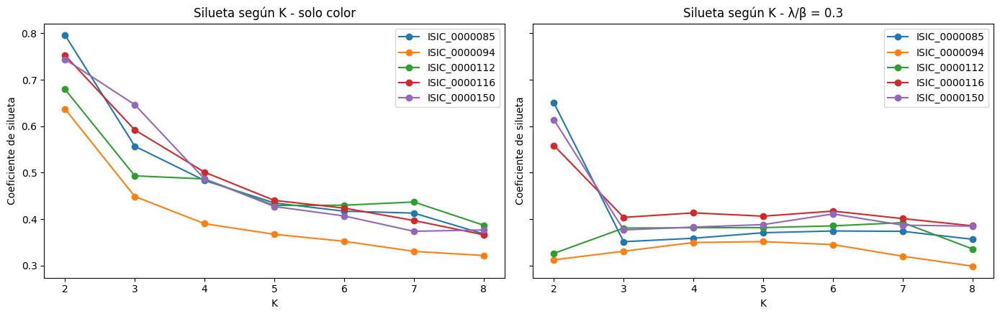

In [9]:
# Silueta segun K para algunas imagenes de ajuste, con solo color y con lam/beta = 0.3
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, (b, l) in zip(axes, [(1, 0), (1, 0.3)]):
    for i in ["0000085", "0000094", "0000112", "0000116", "0000150"]:
        por_k = agrupaciones[(i, b, l)]["por_k"]
        ax.plot(VALORES_K, [por_k[k][1] for k in VALORES_K], marker="o", label=f"ISIC_{i}")
    ax.set_title(f"Silueta según K - {nombre_combinacion(b, l)}")
    ax.set_xlabel("K")
    ax.set_ylabel("Coeficiente de silueta")
    ax.legend()
plt.tight_layout()
plt.show()

Lo más llamativo es que **con poco peso de la posición la silueta escoge casi siempre K = 2**: con solo color y con λ/β = 0.1 sale K = 2 en las 15 imágenes, y con λ/β = 0.2 y 0.3 en 14 y 13 de las 15. Tiene sentido, porque en estas fotos la separación más clara es piel contra lesión, y la silueta premia justamente la división más gruesa y mejor separada. Las excepciones son lesiones pálidas: ISIC_0000094 (K = 4 con λ/β = 0.2 y K = 5 con 0.3) e ISIC_0000112 (K = 7 con λ/β = 0.3). En la gráfica se ve que en esas imágenes la silueta queda más baja y bastante plana para todos los K, entonces cualquier cambio pequeño en la forma de los grupos hace ganar un K más alto.

A medida que la posición pesa más, la silueta promedio baja (de 0.747 con solo color a 0.398 con solo posición) y el K escogido sube a 5 o más desde λ/β = 0.75. Esto pasa porque las coordenadas están repartidas parejo por toda la imagen y no forman grupos naturales, entonces K-medias empieza a partir la imagen en "baldosas". Con solo posición siempre sale K = 4, que es dividir la imagen en cuatro cuadrantes sin importar dónde esté la lesión.

## Actividad 3 - Construcción de la máscara de la lesión

K-medias solo agrupa píxeles, no dice cuál grupo es la lesión. Para decidirlo de forma automática usamos lo que vimos en las imágenes de ajuste: la lesión es **más oscura** que la piel y casi siempre está **cerca del centro**, mientras que el problema típico son las **esquinas negras** que deja el lente del dermatoscopio, que también son oscuras. Comparamos dos criterios:

**Criterio A - grupos oscuros (solo color).** Calculamos la luminancia promedio de cada grupo (Y = 0.299R + 0.587G + 0.114B, usando el color real de los píxeles, sin los pesos β y λ). La lesión son los grupos cuya luminancia está por debajo del punto medio entre el grupo más oscuro y el más claro (que asumimos es la piel). Con K = 2 esto es simplemente "el grupo más oscuro", y con K mayor deja entrar los grupos intermedios que se parecen más a la lesión que a la piel.

**Criterio B - grupos oscuros, centrales y región principal (color + ubicación + tamaño).** Igual que A, pero con dos ajustes:
1. Antes de comparar luminancias descartamos los grupos que tienen más del 50% de sus píxeles en una franja del 10% del ancho y del alto en el borde de la imagen. Esa franja ocupa el 36% de la imagen, entonces un grupo repartido al azar tendría un 36% de sus píxeles ahí. Un grupo con más del 50% está claramente concentrado en el borde, que es lo que pasa con las esquinas negras, mientras que una lesión grande que toca el borde tiene la mayoría de sus píxeles en el centro.
2. De lo que queda nos quedamos con la región conectada más grande y le rellenamos los huecos. La idea es que hay una sola lesión por imagen, entonces las manchas pequeñas sueltas (pecas, esquinas, reflejos) sobran, y los huecos dentro de la lesión (zonas más claras como regresiones o reflejos) sí son parte de ella.

El criterio B usa color, ubicación y tamaño, que son justo las características de los grupos que sugiere el enunciado.

In [10]:
BANDA_BORDE = 0.10          # ancho de la franja del borde (fraccion del alto y del ancho)
MAX_FRACCION_BORDE = 0.50   # un grupo con mas de esta fraccion de pixeles en la franja se descarta


def luminancia(img):
    img = img.astype(float) / 255.0
    return 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]


def luminancia_grupos(img, etiquetas):
    lum = luminancia(img)
    return {g: lum[etiquetas == g].mean() for g in np.unique(etiquetas)}


def fraccion_en_borde(etiquetas, banda=BANDA_BORDE):
    alto, ancho = etiquetas.shape
    franja = np.zeros((alto, ancho), bool)
    bh, bw = int(alto * banda), int(ancho * banda)
    franja[:bh] = franja[-bh:] = True
    franja[:, :bw] = franja[:, -bw:] = True
    return {g: franja[etiquetas == g].mean() for g in np.unique(etiquetas)}


def region_principal(mascara):
    # Se queda con la region conectada mas grande y le rellena los huecos
    if mascara.sum() == 0:
        return mascara
    regiones, n = ndi.label(mascara)
    tamanos = ndi.sum(mascara, regiones, range(1, n + 1))
    principal = regiones == (np.argmax(tamanos) + 1)
    return ndi.binary_fill_holes(principal).astype(np.uint8)


def criterio_oscuros(img, etiquetas):
    lum = luminancia_grupos(img, etiquetas)
    umbral = (min(lum.values()) + max(lum.values())) / 2
    lesion = [g for g, v in lum.items() if v < umbral]
    return np.isin(etiquetas, lesion).astype(np.uint8)


def criterio_oscuros_centro(img, etiquetas, quitar_borde=True, limpiar=True):
    lum = luminancia_grupos(img, etiquetas)
    candidatos = lum
    if quitar_borde:
        borde = fraccion_en_borde(etiquetas)
        candidatos = {g: v for g, v in lum.items() if borde[g] <= MAX_FRACCION_BORDE} or lum
    umbral = (min(candidatos.values()) + max(lum.values())) / 2
    lesion = [g for g, v in candidatos.items() if v < umbral]
    mascara = np.isin(etiquetas, lesion).astype(np.uint8)
    return region_principal(mascara) if limpiar else mascara


CRITERIOS = {
    "A: grupos oscuros": criterio_oscuros,
    "B: oscuros + centro + región principal": criterio_oscuros_centro,
}

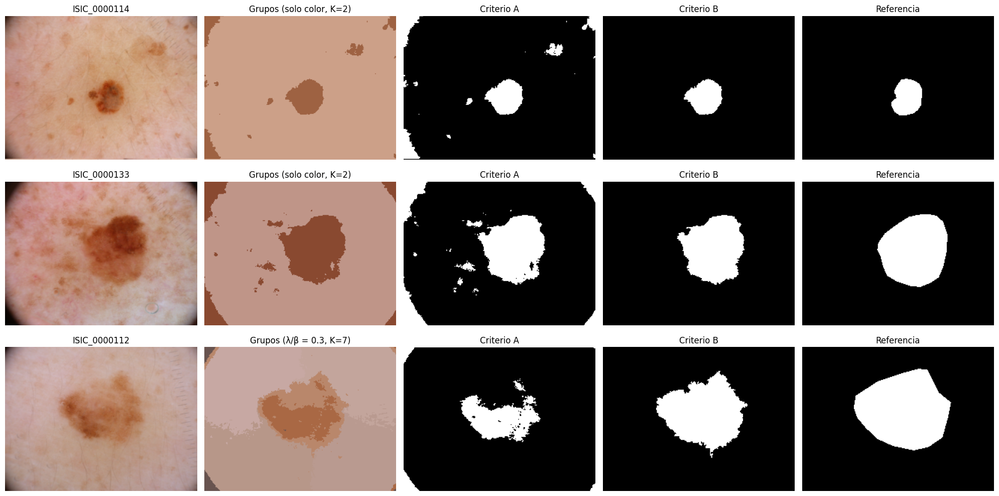

In [11]:
# Ejemplo de los dos criterios en imagenes de ajuste con esquinas oscuras
def colorear_grupos(img, etiquetas):
    # Pinta cada pixel con el color promedio de su grupo
    salida = np.zeros_like(img)
    for g in np.unique(etiquetas):
        salida[etiquetas == g] = img[etiquetas == g].mean(axis=0)
    return salida


ejemplos = [("0000114", 1, 0), ("0000133", 1, 0), ("0000112", 1, 0.3)]
fig, axes = plt.subplots(len(ejemplos), 5, figsize=(20, 3.4 * len(ejemplos)))
for fila, (i, b, l) in zip(axes, ejemplos):
    r = agrupaciones[(i, b, l)]
    paneles = [
        (reducidas[i], f"ISIC_{i}"),
        (colorear_grupos(reducidas[i], r["etiquetas"]), f"Grupos ({nombre_combinacion(b, l)}, K={r['k']})"),
        (criterio_oscuros(reducidas[i], r["etiquetas"]), "Criterio A"),
        (criterio_oscuros_centro(reducidas[i], r["etiquetas"]), "Criterio B"),
        (referencias[i], "Referencia"),
    ]
    for ax, (panel, titulo) in zip(fila, paneles):
        ax.imshow(panel, cmap="gray")
        ax.set_title(titulo)
        ax.axis("off")
plt.tight_layout()
plt.show()

Las tres filas muestran el problema que motivó el criterio B:

- En **ISIC_0000114** e **ISIC_0000133**, con solo color y K = 2, las esquinas negras caen en el mismo grupo que la lesión, porque las dos son oscuras. El criterio A no tiene cómo separarlas y marca como lesión las esquinas y varias pecas sueltas. B se queda con la región conectada más grande, que es la lesión, y descarta lo demás.
- En **ISIC_0000112** (λ/β = 0.3, K = 7) el grupo más oscuro de todos son las esquinas. Con el criterio A el umbral queda a mitad de camino entre las esquinas negras y la piel, entonces solo entran los grupos más oscuros de la lesión y la máscara sale incompleta. B primero descarta el grupo de las esquinas (casi todos sus píxeles están en la franja del borde), entonces el umbral sube y entran también los grupos intermedios de la lesión. Después rellena los huecos y se queda con la región principal.

En los tres casos la máscara de B se parece mucho más a la referencia, aunque en ISIC_0000112 todavía se queda corta en la parte más clara de la lesión.

## Actividad 4 - Ajuste del método

Con las 15 imágenes de ajuste evaluamos las 20 configuraciones (10 combinaciones de β y λ por 2 criterios). Para cada imagen calculamos:

- **Dice** entre la máscara estimada y la de referencia, con `f1_score` sobre las máscaras aplanadas (la lesión es la clase positiva). Es el criterio principal para escoger.
- **V-measure** entre los grupos de K-medias y las etiquetas de referencia. Este no depende del criterio de la máscara, mide qué tanto los grupos por sí solos respetan la división lesión / piel.

In [12]:
def dice(referencia, estimada):
    return f1_score(referencia.ravel(), estimada.ravel(), zero_division=0)


filas = []
for (i, b, l), r in agrupaciones.items():
    vm = v_measure_score(referencias[i].ravel(), r["etiquetas"].ravel())
    for nombre, criterio in CRITERIOS.items():
        estimada = criterio(reducidas[i], r["etiquetas"])
        filas.append({"Imagen": i, "β": b, "λ": l, "Combinación": nombre_combinacion(b, l), "Criterio": nombre,
                      "K": r["k"], "Silueta": r["silueta"], "Dice": dice(referencias[i], estimada),
                      "V-measure": vm})
resultados_ajuste = pd.DataFrame(filas)

resumen_ajuste = (resultados_ajuste
                  .groupby(["β", "λ", "Combinación", "Criterio"])
                  .agg(Dice_promedio=("Dice", "mean"), Dice_std=("Dice", "std"), Dice_mínimo=("Dice", "min"),
                       V_measure_promedio=("V-measure", "mean"), K_promedio=("K", "mean"),
                       Silueta_promedio=("Silueta", "mean"))
                  .sort_values("Dice_promedio", ascending=False)
                  .reset_index())
resumen_ajuste.round(3)

,β,λ,Combinación,Criterio,Dice_promedio,Dice_std,Dice_mínimo,V_measure_promedio,K_promedio,Silueta_promedio
0,1,0.30,λ/β = 0.3,B: oscuros + centro + región principal,0.895,0.058,0.759,0.601,2.533,0.584
1,1,0.20,λ/β = 0.2,B: oscuros + centro + región principal,0.889,0.065,0.759,0.613,2.133,0.646
2,1,0.00,solo color,B: oscuros + centro + región principal,0.885,0.065,0.759,0.637,2.000,0.747
3,1,0.10,λ/β = 0.1,B: oscuros + centro + región principal,0.884,0.065,0.759,0.637,2.000,0.715
4,1,0.50,λ/β = 0.5,B: oscuros + centro + región principal,0.880,0.063,0.744,0.525,3.200,0.493
5,1,0.75,λ/β = 0.75,B: oscuros + centro + región principal,0.870,0.068,0.736,0.329,4.867,0.440
6,1,0.50,λ/β = 0.5,A: grupos oscuros,0.858,0.077,0.737,0.525,3.200,0.493
7,1,0.75,λ/β = 0.75,A: grupos oscuros,0.858,0.069,0.736,0.329,4.867,0.440
8,1,0.20,λ/β = 0.2,A: grupos oscuros,0.851,0.101,0.597,0.613,2.133,0.646
9,1,0.00,solo color,A: grupos oscuros,0.843,0.102,0.599,0.637,2.000,0.747


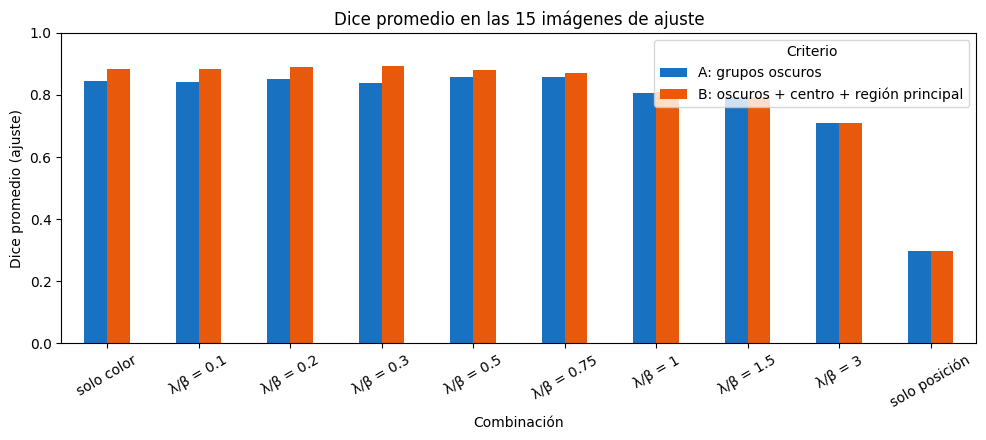

In [13]:
# Dice promedio en ajuste para cada combinacion y criterio
tabla_dice = resultados_ajuste.pivot_table(index="Combinación", columns="Criterio", values="Dice", aggfunc="mean")
tabla_dice = tabla_dice.reindex([nombre_combinacion(b, l) for b, l in COMBINACIONES])

fig, ax = plt.subplots(figsize=(10, 4.5))
tabla_dice.plot(kind="bar", ax=ax, rot=30, color=["#1971C2", "#E8590C"])
ax.set_ylabel("Dice promedio (ajuste)")
ax.set_ylim(0, 1)
ax.set_title("Dice promedio en las 15 imágenes de ajuste")
plt.tight_layout()
plt.show()

Las configuraciones con λ/β entre 0 y 0.5 y el criterio B quedan todas muy cerca, con Dice promedio entre 0.880 y 0.895. La mejor es **λ/β = 0.3 con el criterio B (Dice 0.895, desviación 0.058, mínimo 0.759)**, seguida de λ/β = 0.2 con B (0.889). En todas las combinaciones con λ/β ≤ 1 el criterio B le gana al A, y además baja la variabilidad. Por ejemplo, con λ/β = 0.3 la desviación pasa de 0.127 a 0.058 y el Dice mínimo de 0.545 a 0.759, o sea que B no solo sube el promedio sino que evita los fallos graves.

Desde λ/β = 1 el Dice cae fuerte (0.811 con λ/β = 1 y 0.710 con λ/β = 3), y con solo posición llega a 0.297, porque los grupos ya no siguen el color sino que parten la imagen en regiones. El V-measure baja en el mismo sentido (0.637 con solo color, 0.601 con λ/β = 0.3 y 0.013 con solo posición), pero no ordena las configuraciones igual que el Dice: la de mejor V-measure (solo color) no es la de mejor Dice. Es lo que advierte el enunciado: una agrupación que se parece más a las etiquetas de referencia no necesariamente produce la mejor máscara, porque el Dice también depende de cómo el criterio convierte los grupos en máscara.

### Qué aporta cada parte del criterio B

Para entender de dónde sale la diferencia entre A y B, separamos sus dos ajustes (quitar los grupos del borde y quedarse con la región principal) y los probamos por aparte con la mejor combinación de β y λ y con solo color.

In [14]:
variantes = {
    "A: grupos oscuros": lambda img, et: criterio_oscuros_centro(img, et, quitar_borde=False, limpiar=False),
    "A + quitar grupos del borde": lambda img, et: criterio_oscuros_centro(img, et, quitar_borde=True, limpiar=False),
    "A + región principal": lambda img, et: criterio_oscuros_centro(img, et, quitar_borde=False, limpiar=True),
    "B: los dos ajustes": lambda img, et: criterio_oscuros_centro(img, et, quitar_borde=True, limpiar=True),
}
mejor_combinacion = tuple(resumen_ajuste.loc[0, ["β", "λ"]])
filas = []
for b, l in [mejor_combinacion, (1, 0)]:
    for nombre, f in variantes.items():
        dices = [dice(referencias[i], f(reducidas[i], agrupaciones[(i, b, l)]["etiquetas"])) for i in AJUSTE]
        filas.append({"Combinación": nombre_combinacion(b, l), "Variante": nombre, "Dice promedio": np.mean(dices),
                      "Dice mínimo": np.min(dices)})
pd.DataFrame(filas).pivot_table(index="Variante", columns="Combinación", values=["Dice promedio", "Dice mínimo"]).round(3)

Dice mínimo           Dice promedio          
Combinación                  solo color λ/β = 0.3    solo color λ/β = 0.3
Variante                                                                 
A + quitar grupos del borde       0.599     0.591         0.843     0.859
A + región principal              0.759     0.559         0.885     0.873
A: grupos oscuros                 0.599     0.545         0.843     0.838
B: los dos ajustes                0.759     0.759         0.885     0.895

Las dos partes del criterio B aportan, pero en casos distintos:

- **Quedarse con la región principal** es lo que más ayuda en general. Con solo color sube el Dice de 0.843 a 0.885 y el mínimo de 0.599 a 0.759, porque elimina las esquinas negras y las pecas que caen en el mismo grupo que la lesión cuando K = 2.
- **Quitar los grupos del borde** solo cambia algo cuando K es mayor que 2 y las esquinas quedan en un grupo aparte. Con solo color, que siempre da K = 2, no cambia nada. Con λ/β = 0.3 sube el Dice de 0.838 a 0.859, sobre todo por ISIC_0000112.

Con λ/β = 0.3 las dos partes juntas (0.895) son mejores que cada una por separado (0.859 y 0.873), y es la única variante que no tiene ninguna imagen por debajo de 0.75.

### Verificación de la recomendación de la IAG

Antes de escoger la configuración final hicimos la actividad de verificación: le pedimos a una herramienta de IAG que nos recomendara β, λ, K y un criterio para identificar la lesión, describiendo las imágenes con palabras (sin adjuntarlas ni decir de qué conjunto de datos son). El historial completo está en la sección "Uso de herramientas de IA generativa" y en el archivo `Historial_IAG_verificacion.md`. Acá probamos su recomendación con las mismas 15 imágenes de ajuste.

In [15]:
from skimage.morphology import disk


# Criterio recomendado por la IAG, copiado de su respuesta (solo cambiamos los nombres de algunas variables)
def mascara_lesion_iag(img, labels, K):
    H, W = labels.shape
    L = img @ np.array([0.299, 0.587, 0.114])
    yy, xx = np.mgrid[0:H, 0:W]
    r = np.hypot(xx / (W - 1) - 0.5, yy / (H - 1) - 0.5)

    nk = np.array([np.sum(labels == k) for k in range(K)])
    Lk = np.array([L[labels == k].mean() if nk[k] else 1.0 for k in range(K)])
    fk = np.array([(r[labels == k] > 0.5).mean() if nk[k] else 1.0 for k in range(K)])
    anillo = (r > 0.40) & (r < 0.50)
    piel = np.argmax([np.sum(anillo & (labels == k)) for k in range(K)])

    cand = [k for k in range(K) if nk[k] and not (fk[k] > 0.6 and Lk[k] < Lk[piel])]
    cand = sorted(cand, key=lambda k: Lk[k])
    mejor, corte = -1, 1
    for i in range(1, len(cand)):
        a, b = cand[:i], cand[i:]
        m0 = np.average(Lk[a], weights=nk[a])
        m1 = np.average(Lk[b], weights=nk[b])
        v = nk[a].sum() * nk[b].sum() * (m0 - m1) ** 2
        if v > mejor:
            mejor, corte = v, i
    lesion = [k for k in cand[:corte] if k != piel and Lk[k] < Lk[piel] - 0.03]

    m = ndi.binary_opening(np.isin(labels, lesion), structure=disk(2))
    comp, n = ndi.label(m)
    if n:
        idx = range(1, n + 1)
        sol = np.asarray(ndi.sum(r < 0.25, comp, index=idx))
        if sol.max() == 0:
            sol = np.asarray(ndi.sum(m, comp, index=idx))
        m = comp == (np.argmax(sol) + 1)
    m = ndi.binary_fill_holes(m)
    m = ndi.binary_closing(np.pad(m, 3), structure=disk(3))[3:-3, 3:-3]
    return ndi.binary_fill_holes(m).astype(np.uint8)


def criterio_iag(img, etiquetas):
    return mascara_lesion_iag(img.astype(float) / 255.0, etiquetas, int(etiquetas.max()) + 1)


# Version revisada que propuso la IAG en su segunda respuesta, pensada para K pequeno (sobre todo K = 2):
# solo descarta grupos casi enteros en las esquinas, nunca el unico grupo oscuro, quita los pixeles casi
# negros fuera del circulo inscrito y tiene un respaldo si la mascara cubre menos del 1% o mas del 80%
def mascara_lesion_iag_revisada(img, labels, K):
    H, W = labels.shape
    L = img @ np.array([0.299, 0.587, 0.114])
    yy, xx = np.mgrid[0:H, 0:W]
    r = np.hypot(xx / (W - 1) - 0.5, yy / (H - 1) - 0.5)

    nk = np.array([np.sum(labels == k) for k in range(K)])
    Lk = np.array([L[labels == k].mean() if nk[k] else 1.0 for k in range(K)])
    fk = np.array([(r[labels == k] > 0.5).mean() if nk[k] else 1.0 for k in range(K)])
    anillo = (r > 0.40) & (r < 0.50)
    piel = np.argmax([np.sum(anillo & (labels == k)) for k in range(K)])

    oscuros = [k for k in range(K) if nk[k] and Lk[k] < Lk[piel] - 0.03]
    esquina = [k for k in oscuros if fk[k] > 0.8]
    if len(esquina) == len(oscuros):
        esquina = []
    cand = sorted([k for k in range(K) if nk[k] and k not in esquina], key=lambda k: Lk[k])
    mejor, corte = -1, 1
    for i in range(1, len(cand)):
        a, b = cand[:i], cand[i:]
        m0 = np.average(Lk[a], weights=nk[a])
        m1 = np.average(Lk[b], weights=nk[b])
        v = nk[a].sum() * nk[b].sum() * (m0 - m1) ** 2
        if v > mejor:
            mejor, corte = v, i
    lesion = [k for k in cand[:corte] if k != piel and Lk[k] < Lk[piel] - 0.03]

    m = np.isin(labels, lesion)
    m &= ~((r > 0.5) & (L < 0.15))
    m = ndi.binary_opening(m, structure=disk(2))
    comp, n = ndi.label(m)
    if n:
        idx = range(1, n + 1)
        sol = np.asarray(ndi.sum(r < 0.25, comp, index=idx))
        if sol.max() == 0:
            sol = np.asarray(ndi.sum(m, comp, index=idx))
        m = comp == (np.argmax(sol) + 1)
    m = ndi.binary_fill_holes(m)
    m = ndi.binary_closing(np.pad(m, 3), structure=disk(3))[3:-3, 3:-3]
    m = ndi.binary_fill_holes(m)

    if m.mean() < 0.01 or m.mean() > 0.80:
        if oscuros:
            distancia_centro = {k: np.hypot(xx[labels == k].mean() / (W - 1) - 0.5,
                                            yy[labels == k].mean() / (H - 1) - 0.5) for k in oscuros}
            m = labels == min(distancia_centro, key=distancia_centro.get)
        else:
            m = np.zeros_like(m)
    return m.astype(np.uint8)


def criterio_iag_revisado(img, etiquetas):
    return mascara_lesion_iag_revisada(img.astype(float) / 255.0, etiquetas, int(etiquetas.max()) + 1)


# Probamos la recomendacion en las 15 imagenes de ajuste: tal cual (K = 4 fijo) y adaptada al
# protocolo del laboratorio (K por silueta), y la comparamos con nuestra mejor configuracion
b_mejor, l_mejor, c_mejor = resumen_ajuste.loc[0, ["β", "λ", "Criterio"]]
pruebas_iag = {
    "IAG 1a respuesta tal cual: λ/β = 0.3, K = 4 fijo, criterio IAG":
        lambda i: (agrupaciones[(i, 1, 0.3)]["por_k"][4][0], criterio_iag),
    "IAG 1a respuesta con K por silueta: λ/β = 0.3, criterio IAG":
        lambda i: (agrupaciones[(i, 1, 0.3)]["etiquetas"], criterio_iag),
    "IAG 2a respuesta: λ/β = 0.2, K por silueta, criterio IAG revisado":
        lambda i: (agrupaciones[(i, 1, 0.2)]["etiquetas"], criterio_iag_revisado),
    "Nuestro criterio B con K = 4 fijo (λ/β = 0.3)":
        lambda i: (agrupaciones[(i, 1, 0.3)]["por_k"][4][0], CRITERIOS["B: oscuros + centro + región principal"]),
    f"Nuestra mejor configuración ({nombre_combinacion(b_mejor, l_mejor)}, K por silueta, {c_mejor[:1]})":
        lambda i: (agrupaciones[(i, b_mejor, l_mejor)]["etiquetas"], CRITERIOS[c_mejor]),
}
dice_iag = {}
for nombre, obtener in pruebas_iag.items():
    dice_iag[nombre] = {}
    for i in AJUSTE:
        etiquetas, criterio = obtener(i)
        dice_iag[nombre][f"ISIC_{i}"] = dice(referencias[i], criterio(reducidas[i], etiquetas))
dice_iag = pd.DataFrame(dice_iag)
display(pd.DataFrame({"Dice promedio": dice_iag.mean(), "Dice mínimo": dice_iag.min(),
                      "Imágenes con Dice < 0.7": (dice_iag < 0.7).sum()}).round(3))
dice_iag.round(3)

,Dice promedio,Dice mínimo,Imágenes con Dice < 0.7
"IAG 1a respuesta tal cual: λ/β = 0.3, K = 4 fijo, criterio IAG",0.861,0.610,1
"IAG 1a respuesta con K por silueta: λ/β = 0.3, criterio IAG",0.894,0.758,0
"IAG 2a respuesta: λ/β = 0.2, K por silueta, criterio IAG revisado",0.886,0.758,0
Nuestro criterio B con K = 4 fijo (λ/β = 0.3),0.862,0.613,1
"Nuestra mejor configuración (λ/β = 0.3, K por silueta, B)",0.895,0.759,0


,"IAG 1a respuesta tal cual: λ/β = 0.3, K = 4 fijo, criterio IAG","IAG 1a respuesta con K por silueta: λ/β = 0.3, criterio IAG","IAG 2a respuesta: λ/β = 0.2, K por silueta, criterio IAG revisado",Nuestro criterio B con K = 4 fijo (λ/β = 0.3),"Nuestra mejor configuración (λ/β = 0.3, K por silueta, B)"
ISIC_0000085,0.870,0.901,0.901,0.875,0.906
ISIC_0000086,0.892,0.929,0.929,0.892,0.934
ISIC_0000089,0.975,0.945,0.945,0.974,0.947
ISIC_0000094,0.946,0.938,0.920,0.933,0.922
ISIC_0000108,0.875,0.900,0.900,0.880,0.905
ISIC_0000114,0.874,0.887,0.887,0.875,0.887
ISIC_0000116,0.743,0.758,0.758,0.745,0.759
ISIC_0000122,0.885,0.896,0.895,0.887,0.898
ISIC_0000133,0.808,0.891,0.891,0.814,0.891
ISIC_0000137,0.943,0.956,0.956,0.944,0.956


La recomendación de la IAG funcionó bien en lo general, pero no tal como la dio:

- **Tal cual la primera respuesta** (λ/β = 0.3, K = 4 fijo y su criterio), el Dice promedio fue 0.861, más bajo que el de nuestra configuración (0.895), y con un caso por debajo de 0.7 (ISIC_0000150, 0.610). Fijar K = 4 parte la lesión en más grupos de los necesarios, y en imágenes como ISIC_0000150, ISIC_0000133 e ISIC_0000156 algunas zonas de la lesión terminan del lado de la piel. Nuestro propio criterio B con K = 4 fijo da prácticamente lo mismo (0.862), entonces el problema es fijar K = 4 y no su criterio.
- **Su criterio con K escogido por silueta**, que es lo que exige el protocolo, da 0.894, prácticamente igual al nuestro. Tiene sentido, porque se basa en las mismas ideas: la lesión es más oscura que la piel, las esquinas no son lesión, y hay que quedarse con una región central y rellenarle los huecos.
- **La versión de la segunda respuesta** (λ/β = 0.2 y el criterio ajustado para K pequeño) da 0.886. Es un poco peor que con λ/β = 0.3, sobre todo por ISIC_0000112 (0.778 contra 0.877): con λ/β = 0.2 la silueta escoge K = 2 en esa imagen y se pierde la parte más clara de la lesión.

Como ninguna variante de la IAG supera la configuración que salió de nuestra búsqueda, la configuración final se escoge con la tabla de la actividad 4. En la sección de uso de IA discutimos en qué acertó y en qué falló.

### Configuración final

Escogemos la configuración con mayor Dice promedio en las imágenes de ajuste.

In [16]:
final = resumen_ajuste.loc[0]
BETA_FINAL, LAM_FINAL, CRITERIO_FINAL = final["β"], final["λ"], final["Criterio"]
print(f"Configuración final: β = {BETA_FINAL:g}, λ = {LAM_FINAL:g} (λ/β = {LAM_FINAL / BETA_FINAL:g}), "
      f"K por silueta entre 2 y 8, criterio '{CRITERIO_FINAL}'")
print(f"Dice promedio en ajuste: {final['Dice_promedio']:.3f} (std {final['Dice_std']:.3f}, mínimo {final['Dice_mínimo']:.3f})")
print(f"V-measure promedio en ajuste: {final['V_measure_promedio']:.3f}")

Configuración final: β = 1, λ = 0.3 (λ/β = 0.3), K por silueta entre 2 y 8, criterio 'B: oscuros + centro + región principal'
Dice promedio en ajuste: 0.895 (std 0.058, mínimo 0.759)
V-measure promedio en ajuste: 0.601


In [17]:
# Dice por imagen de ajuste: configuracion final contra solo color y solo posicion (mismo criterio)
por_imagen = resultados_ajuste[resultados_ajuste["Criterio"] == CRITERIO_FINAL].pivot_table(
    index="Imagen", columns="Combinación", values="Dice")
por_imagen = por_imagen[[nombre_combinacion(BETA_FINAL, LAM_FINAL), "solo color", "solo posición"]]
por_imagen["Diferencia final - solo color"] = por_imagen.iloc[:, 0] - por_imagen["solo color"]
k_final = resultados_ajuste[(resultados_ajuste["β"] == BETA_FINAL) & (resultados_ajuste["λ"] == LAM_FINAL)
                            & (resultados_ajuste["Criterio"] == CRITERIO_FINAL)].set_index("Imagen")
por_imagen.insert(0, "K (final)", k_final["K"])
por_imagen.insert(1, "V-measure (final)", k_final["V-measure"])
por_imagen.sort_values(por_imagen.columns[2]).round(3)

Combinación,K (final),V-measure (final),λ/β = 0.3,solo color,solo posición,Diferencia final - solo color
Imagen,,,,,,
0000116,2,0.482,0.759,0.759,0.312,-0.000
0000150,2,0.569,0.788,0.788,0.505,-0.000
0000157,2,0.618,0.855,0.855,0.452,-0.000
0000112,7,0.278,0.879,0.782,0.205,0.097
0000114,2,0.400,0.887,0.887,0.028,-0.001
0000133,2,0.425,0.891,0.892,0.207,-0.001
0000122,2,0.652,0.898,0.899,0.502,-0.001
0000108,2,0.760,0.905,0.904,0.367,0.001
0000085,2,0.754,0.906,0.906,0.174,0.000


### Grupos de las mejores configuraciones y de las que usan solo color o solo posición

Cada píxel se pinta con el color promedio de su grupo, y en verde está el contorno de la máscara de referencia. Mostramos las dos configuraciones con mayor Dice promedio y las de solo color y solo posición. Las dividimos en tres figuras de 5 imágenes para que se alcancen a ver.

Dos configuraciones con mayor Dice promedio:


,Combinación,Criterio,Dice_promedio,V_measure_promedio
0,λ/β = 0.3,B: oscuros + centro + región principal,0.895,0.601
1,λ/β = 0.2,B: oscuros + centro + región principal,0.889,0.613


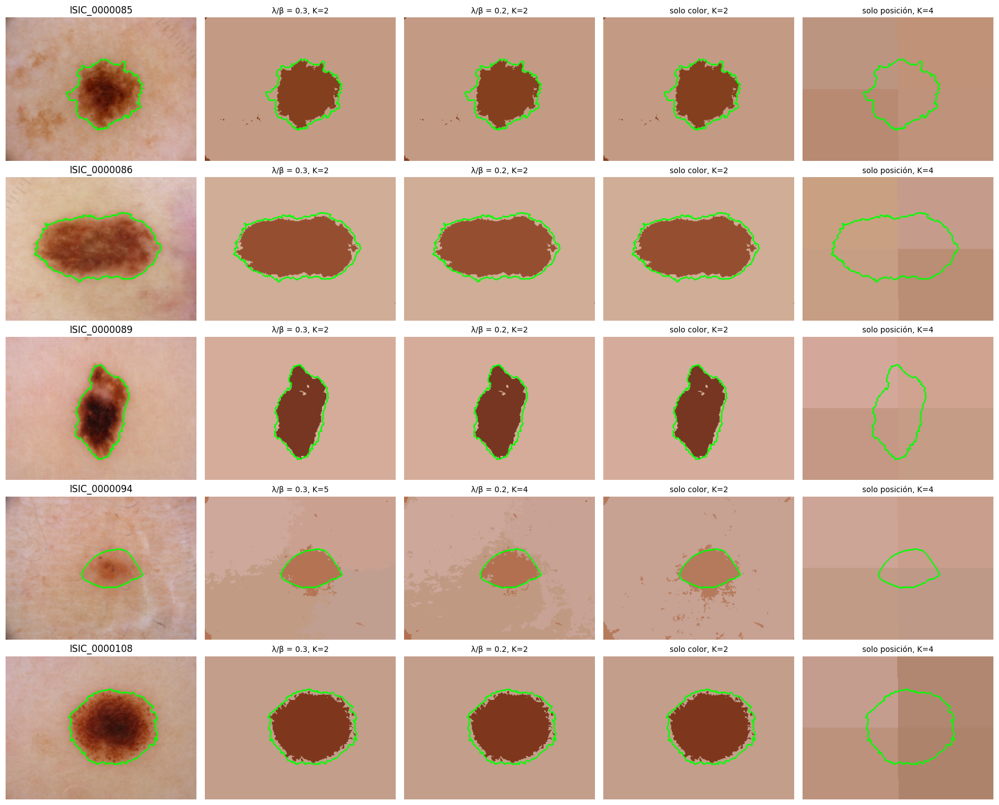

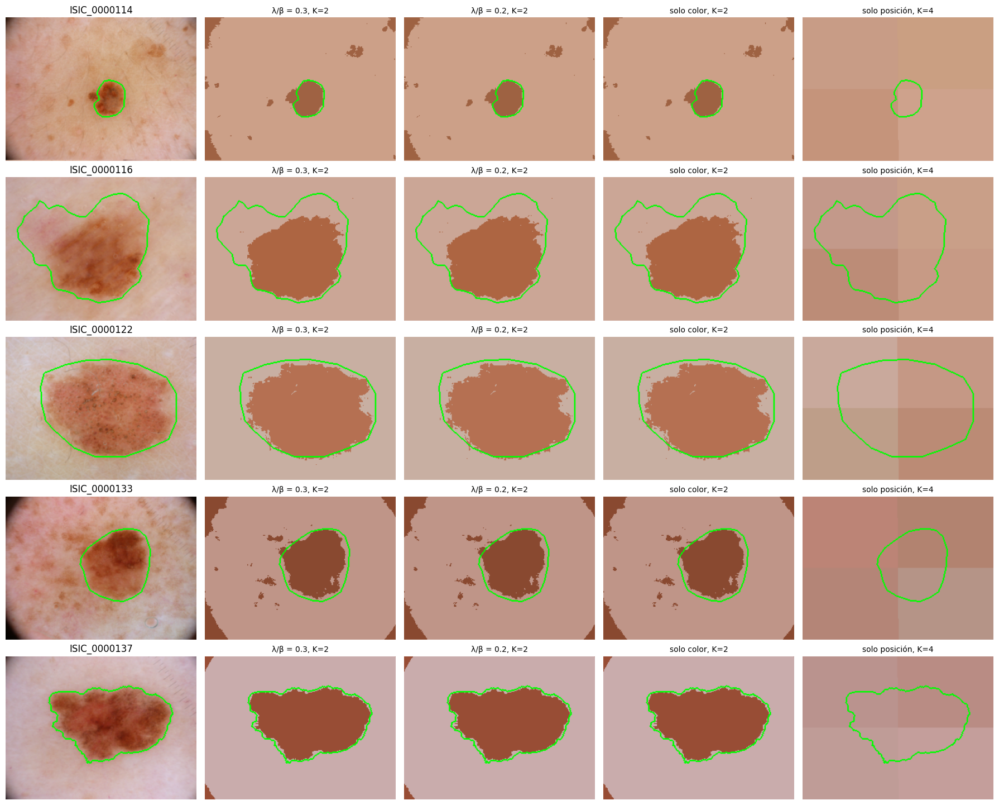

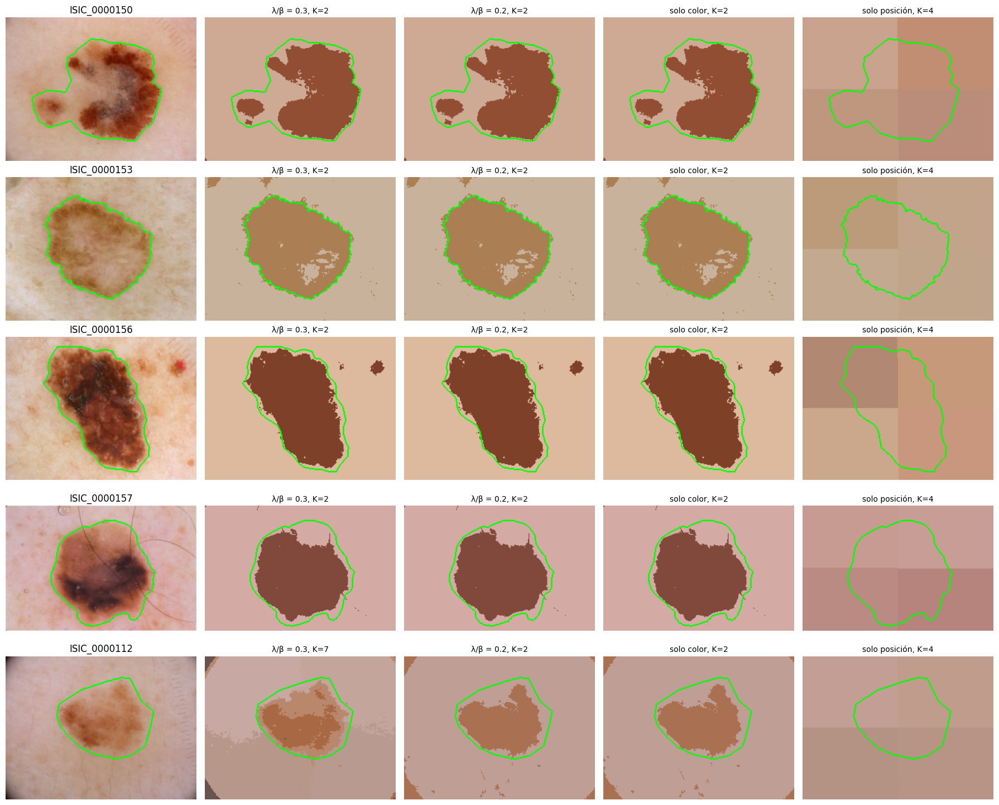

In [18]:
combinaciones_a_mostrar = []
for _, fila in resumen_ajuste.iterrows():
    combinacion = (fila["β"], fila["λ"])
    if combinacion not in combinaciones_a_mostrar:
        combinaciones_a_mostrar.append(combinacion)
    if len(combinaciones_a_mostrar) == 2:
        break
for extra in [(1, 0), (0, 1)]:
    if extra not in combinaciones_a_mostrar:
        combinaciones_a_mostrar.append(extra)
top2 = resumen_ajuste.head(2)
print("Dos configuraciones con mayor Dice promedio:")
display(top2[["Combinación", "Criterio", "Dice_promedio", "V_measure_promedio"]].round(3))

for bloque in range(3):
    ids = AJUSTE[bloque * 5:(bloque + 1) * 5]
    fig, axes = plt.subplots(len(ids), len(combinaciones_a_mostrar) + 1, figsize=(18, 2.9 * len(ids)))
    for fila, i in zip(axes, ids):
        fila[0].imshow(dibujar_contorno(reducidas[i], referencias[i]))
        fila[0].set_title(f"ISIC_{i}")
        for ax, (b, l) in zip(fila[1:], combinaciones_a_mostrar):
            r = agrupaciones[(i, b, l)]
            ax.imshow(dibujar_contorno(colorear_grupos(reducidas[i], r["etiquetas"]), referencias[i]))
            ax.set_title(f"{nombre_combinacion(b, l)}, K={r['k']}", fontsize=10)
        for ax in fila:
            ax.axis("off")
    plt.tight_layout()
    plt.show()

En las figuras se ve por qué las configuraciones con poco peso de la posición dan resultados tan parecidos: con λ/β = 0.3, λ/β = 0.2 y solo color, la silueta escoge K = 2 en casi todas las imágenes y los grupos son prácticamente los mismos, uno café que sigue el contorno de la lesión y otro con la piel. Las diferencias aparecen en las lesiones pálidas (ISIC_0000094 e ISIC_0000112), donde con algo de posición sube el K y la piel se parte en zonas según dónde está, mientras la lesión central queda como un grupo propio. Con solo posición los grupos son los cuatro cuadrantes de la imagen y no tienen nada que ver con la lesión, por eso su Dice es tan bajo.

También se nota que el grupo de la lesión queda un poco por dentro del contorno verde en casi todas las imágenes. El borde de la lesión es más claro y difuso que el centro, y K-medias lo asigna a la piel. Este va a ser el error más repetido del método.

### Casos de fallo en ajuste

Mostramos las tres imágenes de ajuste con menor Dice usando la configuración final.

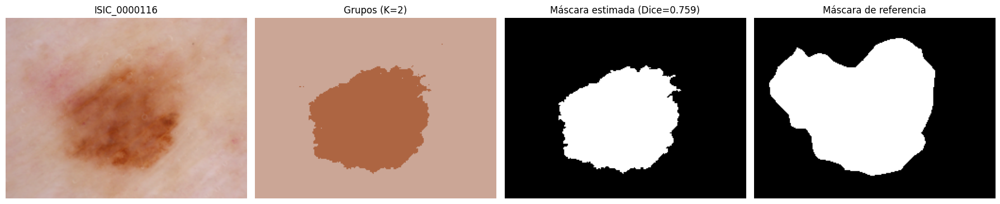

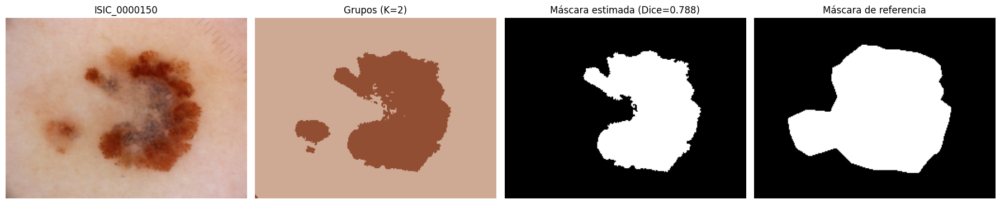

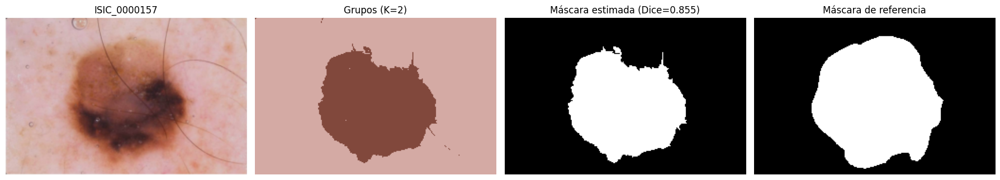

In [19]:
def mostrar_resultado(i, img, etiquetas, estimada, referencia, k, d):
    fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
    paneles = [(img, f"ISIC_{i}"), (colorear_grupos(img, etiquetas), f"Grupos (K={k})"),
               (estimada, f"Máscara estimada (Dice={d:.3f})"), (referencia, "Máscara de referencia")]
    for ax, (panel, titulo) in zip(axes, paneles):
        ax.imshow(panel, cmap="gray")
        ax.set_title(titulo)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


peores = por_imagen.sort_values(por_imagen.columns[2]).index[:3]
for i in peores:
    r = agrupaciones[(i, BETA_FINAL, LAM_FINAL)]
    estimada = CRITERIOS[CRITERIO_FINAL](reducidas[i], r["etiquetas"])
    mostrar_resultado(i, reducidas[i], r["etiquetas"], estimada, referencias[i], r["k"], dice(referencias[i], estimada))

Los tres peores casos de ajuste muestran tres formas distintas de fallar:

- **ISIC_0000116 (Dice 0.759).** Es una lesión grande y pálida cuyo borde se desvanece poco a poco en la piel, con una zona rojiza arriba a la izquierda. K-medias solo separa la parte central más pigmentada, entonces la máscara se queda corta: el dermatólogo marcó una región bastante más amplia de la que se distingue por color.
- **ISIC_0000150 (Dice 0.788).** La lesión tiene un centro gris claro y una parte separada a la izquierda. El grupo oscuro deja por fuera la zona gris, y la región principal descarta la mancha de la izquierda porque no está conectada con el resto. El dermatólogo dibujó todo como una sola lesión.
- **ISIC_0000157 (Dice 0.855).** Los vellos oscuros que cruzan la lesión quedan en el mismo grupo que ella y en el borde superior aparecen salientes delgados que no son lesión. Además los bordes izquierdo e inferior, más claros, quedan por fuera.

En los tres casos el error principal es de **subsegmentación**: el método marca como lesión menos área de la que marcó el especialista, sobre todo en los bordes y en las zonas claras de la lesión.

### ¿El K que escoge la silueta es el que da mejor Dice?

Como guardamos los grupos para todos los K, podemos ver qué Dice se habría obtenido con cada K usando la configuración final. Esto es solo para el análisis (usa las máscaras de referencia de ajuste), el método sigue escogiendo K con la silueta.

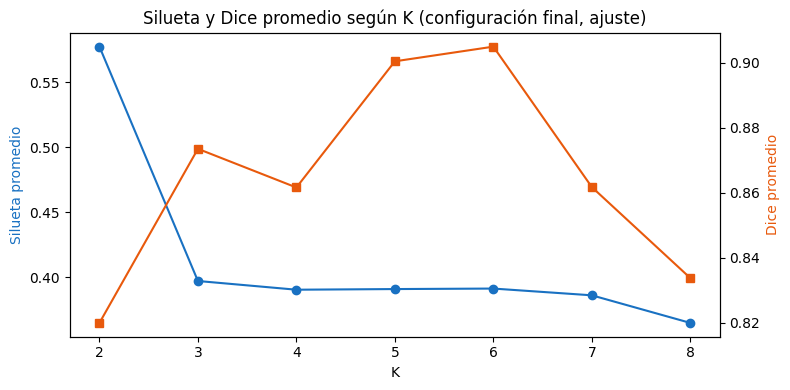

,K silueta,Dice con K silueta,K con mejor Dice,Mejor Dice posible
Imagen,,,,
0000085,2,0.906,6,0.949
0000086,2,0.934,5,0.976
0000089,2,0.947,6,0.974
0000094,5,0.922,4,0.933
0000108,2,0.905,5,0.961
0000112,7,0.879,7,0.879
0000114,2,0.887,2,0.887
0000116,2,0.759,6,0.834
0000122,2,0.898,6,0.915


Dice promedio escogiendo K con la silueta: 0.895
Dice promedio si se escogiera el mejor K de cada imagen: 0.929
Correlación entre silueta y Dice (todas las imágenes y K): 0.214


In [20]:
filas = []
for i in AJUSTE:
    por_k = agrupaciones[(i, BETA_FINAL, LAM_FINAL)]["por_k"]
    for k in VALORES_K:
        etiquetas, sil = por_k[k]
        estimada = CRITERIOS[CRITERIO_FINAL](reducidas[i], etiquetas)
        filas.append({"Imagen": i, "K": k, "Silueta": sil, "Dice": dice(referencias[i], estimada)})
por_k_final = pd.DataFrame(filas)

promedios_k = por_k_final.groupby("K")[["Silueta", "Dice"]].mean()
fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(promedios_k.index, promedios_k["Silueta"], marker="o", color="#1971C2", label="Silueta promedio")
ax1.set_xlabel("K")
ax1.set_ylabel("Silueta promedio", color="#1971C2")
ax2 = ax1.twinx()
ax2.plot(promedios_k.index, promedios_k["Dice"], marker="s", color="#E8590C", label="Dice promedio")
ax2.set_ylabel("Dice promedio", color="#E8590C")
plt.title("Silueta y Dice promedio según K (configuración final, ajuste)")
fig.tight_layout()
plt.show()

k_silueta = por_k_final.loc[por_k_final.groupby("Imagen")["Silueta"].idxmax()].set_index("Imagen")
k_dice = por_k_final.loc[por_k_final.groupby("Imagen")["Dice"].idxmax()].set_index("Imagen")
comparacion_k = pd.DataFrame({"K silueta": k_silueta["K"], "Dice con K silueta": k_silueta["Dice"],
                              "K con mejor Dice": k_dice["K"], "Mejor Dice posible": k_dice["Dice"]})
display(comparacion_k.round(3))
print(f"Dice promedio escogiendo K con la silueta: {comparacion_k['Dice con K silueta'].mean():.3f}")
print(f"Dice promedio si se escogiera el mejor K de cada imagen: {comparacion_k['Mejor Dice posible'].mean():.3f}")
print(f"Correlación entre silueta y Dice (todas las imágenes y K): {por_k_final['Silueta'].corr(por_k_final['Dice']):.3f}")

La silueta y el Dice no van de la mano. La silueta promedio es máxima con K = 2 (0.58) y cae por debajo de 0.40 desde K = 3, mientras que el Dice promedio para un K fijo es justamente el más bajo con K = 2 (0.82) y el más alto con K = 5 y 6 (cerca de 0.90). La correlación entre silueta y Dice sobre todas las imágenes y valores de K es apenas 0.214.

Aun así, escoger K con la silueta funciona bien (Dice promedio de 0.895, mejor que cualquier K fijo), porque la silueta escoge K = 2 donde K = 2 sirve y sube K justo en las dos imágenes pálidas donde K = 2 falla (ISIC_0000094 e ISIC_0000112). Si se escogiera el mejor K de cada imagen mirando las máscaras se llegaría a 0.929, pero eso no se puede hacer en la práctica porque usa la respuesta correcta.

¿Por qué K = 5 o 6 dan mejor Dice? Con más grupos, el borde claro de la lesión queda en un grupo intermedio que el criterio todavía considera más cercano a la lesión que a la piel, y entra en la máscara. Pero eso es justo lo que la silueta castiga, porque ese grupo intermedio no está bien separado de los otros dos.

## Actividad 5 - Evaluación con las imágenes de prueba

Aplicamos la configuración final, sin cambiar nada, a las 5 imágenes de prueba. Es la primera vez que se cargan estas imágenes y sus máscaras en el notebook.

In [21]:
imagenes_prueba = {i: cargar_imagen(i) for i in PRUEBA}
mascaras_prueba = {i: cargar_mascara(i) for i in PRUEBA}

pipe_final = crear_pipeline(beta=BETA_FINAL, lam=LAM_FINAL)
resultados_prueba, salidas_prueba = [], {}
for i in PRUEBA:
    reducida = pipe_final.named_steps["redimension"].transform(imagenes_prueba[i])
    forma = reducida.shape[:2]
    k, por_k = agrupar(pipe_final.fit_transform(imagenes_prueba[i]))
    etiquetas = por_k[k]["etiquetas"].reshape(forma)
    estimada = CRITERIOS[CRITERIO_FINAL](reducida, etiquetas)
    referencia = preparar_mascara(mascaras_prueba[i], forma)
    salidas_prueba[i] = (reducida, etiquetas, estimada, referencia, k)
    resultados_prueba.append({
        "Imagen": f"ISIC_{i}", "K": k, "Silueta": por_k[k]["silueta"],
        "Dice": dice(referencia, estimada),
        "V-measure": v_measure_score(referencia.ravel(), etiquetas.ravel()),
        "Precisión": precision_score(referencia.ravel(), estimada.ravel(), zero_division=0),
        "Recall": recall_score(referencia.ravel(), estimada.ravel(), zero_division=0),
        "% lesión real": referencia.mean() * 100,
        "% lesión estimada": estimada.mean() * 100,
    })
tabla_prueba = pd.DataFrame(resultados_prueba)
fila_promedio = tabla_prueba.drop(columns="Imagen").mean().to_frame().T
fila_promedio.insert(0, "Imagen", "Promedio")
pd.concat([tabla_prueba, fila_promedio], ignore_index=True).round(3)

,Imagen,K,Silueta,Dice,V-measure,Precisión,Recall,% lesión real,% lesión estimada
0,ISIC_0000087,2.0,0.610,0.883,0.635,1.000,0.790,38.334,30.288
1,ISIC_0000105,2.0,0.665,0.917,0.744,1.000,0.848,7.031,5.959
2,ISIC_0000110,2.0,0.554,0.755,0.319,1.000,0.607,10.514,6.382
3,ISIC_0000123,2.0,0.643,0.898,0.693,0.849,0.954,18.667,20.970
4,ISIC_0000128,2.0,0.662,0.935,0.824,1.000,0.879,15.013,13.190
5,Promedio,2.0,0.627,0.878,0.643,0.970,0.815,17.912,15.358


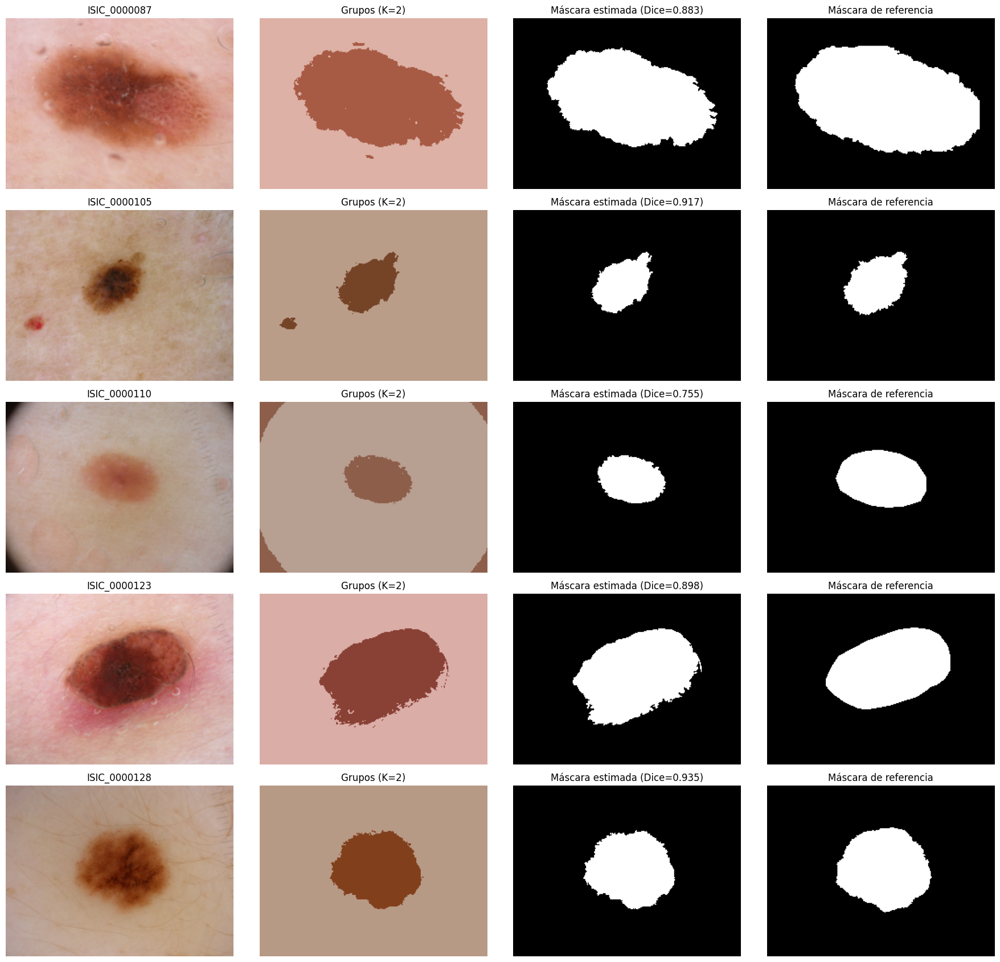

In [22]:
fig, axes = plt.subplots(len(PRUEBA), 4, figsize=(18, 3.4 * len(PRUEBA)))
for fila, i in zip(axes, PRUEBA):
    reducida, etiquetas, estimada, referencia, k = salidas_prueba[i]
    d = dice(referencia, estimada)
    paneles = [(reducida, f"ISIC_{i}"), (colorear_grupos(reducida, etiquetas), f"Grupos (K={k})"),
               (estimada, f"Máscara estimada (Dice={d:.3f})"), (referencia, "Máscara de referencia")]
    for ax, (panel, titulo) in zip(fila, paneles):
        ax.imshow(panel, cmap="gray")
        ax.set_title(titulo)
        ax.axis("off")
plt.tight_layout()
plt.show()

In [23]:
# Comparacion del Dice promedio entre ajuste y prueba con la configuracion final
dice_ajuste = resultados_ajuste[(resultados_ajuste["β"] == BETA_FINAL) & (resultados_ajuste["λ"] == LAM_FINAL)
                                & (resultados_ajuste["Criterio"] == CRITERIO_FINAL)]["Dice"]
pd.DataFrame({
    "Conjunto": ["Ajuste (15 imágenes)", "Prueba (5 imágenes)"],
    "Dice promedio": [dice_ajuste.mean(), tabla_prueba["Dice"].mean()],
    "Dice std": [dice_ajuste.std(), tabla_prueba["Dice"].std()],
    "Dice mínimo": [dice_ajuste.min(), tabla_prueba["Dice"].min()],
    "Dice máximo": [dice_ajuste.max(), tabla_prueba["Dice"].max()],
}).round(3)

,Conjunto,Dice promedio,Dice std,Dice mínimo,Dice máximo
0,Ajuste (15 imágenes),0.895,0.058,0.759,0.973
1,Prueba (5 imágenes),0.878,0.071,0.755,0.935


En las 5 imágenes de prueba la silueta escogió K = 2 en todas, y el Dice promedio fue **0.878**, muy cerca del 0.895 de ajuste. La diferencia (0.017) es menor que la desviación estándar del ajuste (0.058), y el rango también es parecido: de 0.755 a 0.935 en prueba y de 0.759 a 0.973 en ajuste.

**Aciertos.** ISIC_0000128 (0.935) e ISIC_0000105 (0.917) son lesiones oscuras, con buen contraste y bien centradas, que es justo el caso para el que se diseñó el método. En ISIC_0000105 además hay un punto rojo abajo a la izquierda que K-medias puso en el mismo grupo que la lesión, pero la región principal lo descartó. En ISIC_0000110 las esquinas negras también cayeron en el grupo de la lesión y el criterio B las quitó.

**Errores.** El patrón es muy claro en la tabla: la **precisión es casi perfecta** (1.0 en cuatro de las cinco imágenes) pero el **recall es más bajo** (0.815 en promedio). O sea que casi todo lo que el método marca como lesión sí lo es, pero se le escapa parte de la lesión, sobre todo el borde. El peor caso es ISIC_0000110 (Dice 0.755, recall 0.607), una lesión pálida y rosada cuyo halo exterior más claro quedó con la piel: la máscara estimada cubre el 6.4% de la imagen cuando la real cubre el 10.5%. En ISIC_0000087 pasa lo mismo con la parte derecha de la lesión, más clara y rojiza (recall 0.790). La única imagen con precisión menor que 1 es ISIC_0000123 (0.849), donde la piel enrojecida alrededor de la lesión es más oscura que la piel normal y una parte quedó dentro de la máscara.

# Análisis de resultados

### 1. ¿Qué efecto tuvo incluir la posición de los píxeles? Expliquen en qué imágenes mejoró o perjudicó la segmentación y por qué.

En nuestro caso la posición ayudó poco y solo en dosis pequeñas. Con el criterio B, el Dice promedio con λ/β entre 0.1 y 0.3 fue de 0.884 a 0.895, contra 0.885 con solo color. Desde λ/β = 1 empeoró mucho: 0.811 con λ/β = 1, 0.710 con λ/β = 3 y 0.297 con solo posición.

**Dónde mejoró.** Comparando la configuración final (λ/β = 0.3) con solo color imagen por imagen, la diferencia es prácticamente cero en 13 de las 15 imágenes de ajuste. En esas, la silueta escoge K = 2 en los dos casos y los grupos son casi iguales, porque la diferencia de color entre lesión y piel pesa mucho más que la posición. Las dos que mejoran son lesiones pálidas: ISIC_0000112 (de 0.782 a 0.879) e ISIC_0000094 (de 0.864 a 0.922). En las dos, la posición cambia la forma de los grupos lo suficiente para que la silueta escoja un K mayor (7 y 5). La piel se parte en varias zonas según dónde está (incluyendo un grupo para las esquinas oscuras de ISIC_0000112) y la lesión central queda en uno o varios grupos propios que el criterio B junta. Con más peso en la posición también mejoran un poco las lesiones grandes y centradas con esquinas oscuras, como ISIC_0000133 (0.92 con λ/β = 1.5 contra 0.89 con solo color), porque la posición ayuda a mandar las esquinas a otro grupo.

**Dónde perjudicó.** Con mucho peso en la posición los grupos empiezan a seguir regiones del espacio en vez del color. Las más afectadas son la lesión pequeña ISIC_0000114, que ocupa el 3% de la imagen y cae de 0.89 a 0.18 con λ/β = 1, y la lesión pálida ISIC_0000094, que cae a 0.13 con λ/β = 3. En las dos, el grupo que contiene la lesión también se lleva una buena parte de la piel de alrededor. El extremo es solo posición, que parte la imagen en cuadrantes y no supera un Dice de 0.51 en ninguna imagen.

El motivo de fondo es que la posición no tiene grupos naturales (los píxeles están repartidos parejo por toda la imagen) y la lesión está rodeada de piel por todos lados, entonces el centro de la lesión y el de la piel quedan casi en el mismo punto. La posición no ayuda a separar lesión de piel, a lo sumo ayuda a separar lo que está en el centro de lo que está en las esquinas.

### 2. ¿Qué relación encontraron entre K, la silueta y el Dice? ¿Por qué estas métricas no necesariamente conducen a las mismas decisiones?

Encontramos que van en direcciones casi opuestas. Con la configuración final, la silueta promedio es máxima con K = 2 (0.58) y baja a menos de 0.40 desde K = 3. El Dice promedio para un K fijo, en cambio, es el más bajo con K = 2 (0.82) y el más alto con K = 5 y 6 (cerca de 0.90). La correlación entre las dos métricas, sobre todas las imágenes y valores de K, es de apenas 0.214. Igual, escoger K por silueta dio un Dice de 0.895, mejor que cualquier K fijo, porque en las dos imágenes donde K = 2 falla (las pálidas) la silueta también prefirió un K más alto. El mejor K posible por imagen, escogido mirando las máscaras, habría dado 0.929.

No llevan a las mismas decisiones porque miden cosas distintas:

- **La silueta** solo mira qué tan compactos y separados quedan los grupos en el espacio [β·R, β·G, β·B, λ·x, λ·y]. No sabe nada de la lesión. Premia la división más evidente, que en estas fotos es "oscuro contra claro", y castiga los grupos intermedios porque quedan pegados a sus vecinos.
- **El Dice** mide si la máscara que sale de esos grupos coincide con la que dibujó el dermatólogo. Esa máscara incluye el borde difuso de la lesión, que por color está a mitad de camino entre la lesión y la piel. Para capturarlo hace falta justamente un grupo intermedio, que es lo que la silueta no quiere.
- Además, **el Dice depende del criterio de la máscara** y no solo de los grupos. Una misma agrupación puede dar un Dice muy distinto con A o con B, mientras que su silueta es la misma.

Por eso la silueta sirve para escoger K sin usar las máscaras, que es lo que exige el protocolo, pero no garantiza la mejor segmentación.

### 3. ¿Cómo se comparan los resultados de ajuste y prueba? ¿Por qué es importante no modificar el método después de consultar las máscaras de prueba?

Se comparan muy bien. El Dice promedio fue 0.895 en ajuste y 0.878 en prueba, una diferencia de 0.017, menor que la desviación estándar entre imágenes de ajuste (0.058). Los rangos también son parecidos (0.759 a 0.973 en ajuste y 0.755 a 0.935 en prueba), y los tipos de error se repiten: en las dos partes los peores casos son lesiones pálidas o con borde difuso (ISIC_0000116 en ajuste, ISIC_0000110 en prueba). Que el Dice baje un poco en prueba es lo esperable, porque la configuración se escogió como la mejor entre 20 opciones mirando las imágenes de ajuste, y eso siempre favorece un poco al conjunto con el que se escogió. Igual hay que tener cuidado con la conclusión: son solo 5 imágenes de prueba, así que el 0.878 tiene bastante incertidumbre (una sola imagen difícil más lo podría bajar varios puntos).

**Por qué no modificar el método después de ver las máscaras de prueba.** Las imágenes de prueba hacen el papel de "imágenes nuevas de DermAlpes" y sirven para estimar honestamente cómo le iría al método con imágenes que nunca vio. Si después de ver un mal resultado en prueba cambiáramos λ, el umbral o el criterio para arreglarlo, la prueba pasaría a ser parte del ajuste y el 0.878 dejaría de ser una estimación honesta: sería optimista, porque estaríamos midiendo qué tan bien nos acomodamos a esas 5 imágenes específicas y no qué tan bien generaliza el método. Por ejemplo, con lo que vimos en ISIC_0000110 sería tentador agrandar la máscara, pero eso ya sería ajustar con la prueba. Por eso en el notebook las imágenes de prueba solo se cargan en la actividad 5, cuando la configuración ya está fija.

### 4. Identifiquen dos limitaciones de su modelo y expliquen sus posibles causas a partir de las imágenes y de la representación RGB + posición.

**Limitación 1: subsegmentación del borde de la lesión.** El método casi nunca marca piel como lesión (precisión promedio de 0.970 en prueba), pero se le escapa parte de la lesión (recall de 0.815, y 0.607 en ISIC_0000110). Pasa en casi todas las imágenes: el grupo de la lesión queda por dentro del contorno del dermatólogo, y en lesiones pálidas como ISIC_0000116 e ISIC_0000110 se pierde bastante área. Las causas vienen de la representación:
- Cada píxel se describe solo con su color RGB y su posición, sin información de su vecindario ni de textura. El borde de una lesión es una transición gradual, y los píxeles de esa transición tienen un color intermedio que K-medias asigna al centroide más cercano, que suele ser la piel porque la piel es mucho más grande y su centroide queda más "aclarado".
- La silueta favorece K = 2, que es justo el K que no tiene un grupo intermedio para ese borde.
- El dermatólogo dibuja el contorno exterior de toda la lesión, incluyendo zonas claras (como el centro gris de ISIC_0000150), mientras que el método solo puede seguir lo que es más oscuro que la piel.

**Limitación 2: no distingue la lesión de otras cosas oscuras.** RGB + posición no puede diferenciar un píxel de lesión de un píxel de vello, de una esquina negra del dermatoscopio, de una peca o de piel enrojecida, si tienen un color parecido. En ISIC_0000157 los vellos quedan en el grupo de la lesión, en ISIC_0000114, ISIC_0000133 e ISIC_0000110 las esquinas negras caen en el mismo grupo que la lesión, y en ISIC_0000123 la piel enrojecida alrededor de la lesión entra en la máscara. Lo que salva estos casos no es la agrupación sino las suposiciones del criterio B (hay una sola lesión, es la región más grande y no está pegada al borde). Esas suposiciones se rompen si la lesión toca el borde de la foto, si hay dos lesiones o si la lesión está separada en partes (como la mancha de la izquierda en ISIC_0000150, que se descartó).

### 5. En el contexto de DermAlpes, ¿qué consecuencias podrían tener los falsos positivos y falsos negativos? ¿Qué sesgos y problemas de generalización deben considerarse antes de utilizar el método con nuevas poblaciones o condiciones de adquisición?

**Falsos negativos (lesión que el método marca como piel).** Son el error más común de nuestro método. Hacen que la lesión se vea más pequeña y con un borde más regular de lo que es, y eso es delicado porque el dermatólogo justamente quiere medir tamaño y forma: el diámetro, la asimetría y la irregularidad del borde son señales de alarma en la evaluación de lesiones como el melanoma. Una máscara recortada podría hacer que una lesión preocupante parezca más inofensiva, o esconder que creció entre dos consultas. Si el especialista confía en la máscara y no mira la imagen completa, se podría retrasar una atención que sí se necesitaba.

**Falsos positivos (piel, vellos, esquinas o enrojecimiento marcados como lesión).** Inflan el tamaño y deforman el contorno, como pasó con la piel enrojecida en ISIC_0000123. Esto puede llevar a alarmas innecesarias, a pedir más exámenes o biopsias de los que hacen falta, y a que los médicos dejen de confiar en la herramienta. En general es menos grave que un falso negativo, pero tampoco es gratis.

Por eso la herramienta tiene que presentarse como un apoyo: el dermatólogo siempre debería ver la imagen original con el contorno encima y poder corregirlo.

**Sesgos y problemas de generalización a considerar:**
- **Tono de piel.** Todas las imágenes con las que ajustamos son de piel clara, y los conjuntos públicos de dermatoscopia como este tienen muy pocas imágenes de piel oscura. Nuestro criterio se basa en que la lesión es más oscura que la piel. En personas de piel más oscura, que en los municipios donde trabaja DermAlpes pueden ser una parte importante de los pacientes, el contraste es menor y el método podría fallar mucho más, justo con pacientes que ya tienen menos acceso a especialistas.
- **Condiciones de adquisición.** Un dermatoscopio distinto (otra iluminación, luz polarizada o no, otro balance de color, más o menos viñeteado), otra cámara o un personal que no centra la lesión en la foto cambian los colores y la posición en los que se apoya el método. El criterio B supone que la lesión está cerca del centro y lejos del borde.
- **Tipo de lesiones.** Nuestras imágenes casi siempre tienen una sola lesión pigmentada café. Lesiones poco pigmentadas (rosadas o del color de la piel), lesiones muy grandes que tocan el borde o varias lesiones en la misma foto no están bien representadas.
- **Tamaño de la muestra.** La configuración se escogió con 15 imágenes y se probó con 5. Es muy poco para saber qué tan estable es el método, y el umbral de luminancia y la franja del borde quedaron ajustados a esas imágenes.
- **Referencias.** Las máscaras de referencia las hizo una persona y otro dermatólogo podría dibujar el borde distinto, sobre todo en lesiones de borde difuso, que es donde más fallamos.

Antes de usarlo con pacientes, DermAlpes debería validar el método con una muestra de sus propias imágenes (de sus centros de salud, sus equipos y su población), revisando el desempeño por separado según el tono de piel y el tipo de lesión.

# Uso de herramientas de IA generativa

**Herramienta y tipo de uso.** Usamos Claude (Anthropic) a través de Claude Code en Visual Studio Code, de dos formas distintas:

1. **Como apoyo para desarrollar el laboratorio.** Preparó la carpeta de datos: filtró las 20 imágenes del enunciado entre las 900 del conjunto y consiguió sus máscaras de referencia, que no venían en la carpeta. También ayudó a mejorar el código del pipeline, de las búsquedas y de las visualizaciones, y nos apoyó en la redacción de los análisis a partir de los resultados del notebook.
2. **Para la actividad de verificación.** Abrimos una sesión nueva e independiente de Claude, sin acceso a las imágenes ni al resto del laboratorio, y le pedimos una recomendación de β, λ, K y de un criterio para construir la máscara. El historial completo está más abajo y en el archivo `Historial_IAG_verificacion.md`.

**Prompts principales utilizados.**
- Desarrollo: "A partir del el enunciado del laboratorio 4 y de nuestra primera versión, mejora la redacción y verifica los resultados. Si se puede mejorar el pipeline, propon una idea para nosotros verificar y dar o no vía libre para implementarla."
- Verificación: los dos mensajes que aparecen textualmente en el historial de abajo. En ninguno se adjuntaron imágenes ni se mencionó el nombre del conjunto de datos, solo se describieron las imágenes.

### Actividad de verificación

**¿La recomendación funcionó en nuestras imágenes?** En parte. Su criterio para construir la máscara funcionó muy bien: con K escogido por silueta dio un Dice promedio de 0.894 en las imágenes de ajuste, prácticamente igual a nuestra mejor configuración (0.895). Pero la recomendación completa, tal como la dio en la primera respuesta (K = 4 fijo), dio 0.861, y su ajuste de la segunda respuesta (bajar λ/β a 0.2) dio 0.886. Ninguna de las dos superó lo que ya teníamos.

**¿En qué acertó?**
- Que lo que importa es la razón λ/β y que debía ser bastante menor que 1, en un rango de 0.2 a 0.5. Nuestra búsqueda encontró lo mismo (los mejores resultados con λ/β = 0.3 y 0.2, y una caída fuerte desde λ/β = 1).
- Que con mucho peso en la posición K-medias corta la imagen en "baldosas" en vez de separar lesión y piel. Es justo lo que vimos con λ/β ≥ 1 y con solo posición.
- En la segunda respuesta anticipó bien que la silueta escogería K = 2 en la mayoría de las imágenes (pasó en 13 de 15) y K más alto en las lesiones pálidas (pasó en ISIC_0000094 e ISIC_0000112).
- Su criterio usa las mismas ideas que nuestro criterio B: la lesión es más oscura que la piel, hay que descartar las esquinas, quedarse con una sola región central y rellenar huecos. Que dos criterios hechos por separado lleguen a las mismas ideas y casi al mismo Dice nos da más confianza en el criterio.

**¿En qué falló?**
- Recomendó K = 4 diciendo que K = 2 "falla en los casos difíciles" porque el grupo oscuro se lleva las esquinas negras. En nuestras imágenes eso sí pasa, pero la limpieza de la máscara lo resuelve (ISIC_0000114 y ISIC_0000133 quedan con Dice de 0.89 con K = 2). En cambio, K = 4 fijo empeoró varias imágenes (ISIC_0000150 bajó a 0.610). Además, fijar K no se puede según el protocolo, que pide escoger K con la silueta.
- En la segunda respuesta recomendó bajar λ/β de 0.3 a 0.2 para que dominara el color, y eso empeoró el resultado. En ISIC_0000112 la posición era justamente lo que hacía que la silueta escogiera un K mayor y se recuperara la parte clara de la lesión.
- Sugirió preprocesar la imagen (filtro de mediana, quitar la viñeta antes de agrupar), que no se puede porque la representación tiene que ser RGB + posición.
- Aunque no le dijimos el nombre del conjunto, en la primera respuesta lo adivinó ("por ejemplo, de ISIC"), lo que muestra que estas imágenes son muy típicas de los datos públicos con los que se entrenan estos modelos.

**¿Por qué la IAG no podía anticipar el comportamiento del método en nuestras imágenes?** Porque nunca las vio, y el resultado depende de detalles que solo aparecen al probar: qué tan pálidas son las lesiones, cuánto contraste tienen con la piel, qué tan grandes son las esquinas negras, cómo se reparten los colores en cada foto y, sobre todo, cómo interactúan λ, la silueta y el K escogido en cada imagen. Por ejemplo, era imposible saber de antemano que en ISIC_0000112 pasar de λ/β = 0.3 a 0.2 cambiaría el K de 7 a 2. Tampoco podía saber cómo dibujaron los dermatólogos las máscaras de referencia, que incluyen bordes difusos que el color no separa. Lo que la IAG da son valores razonables según cómo funcionan K-medias y la silueta en general, y ella misma lo advirtió ("son puntos de partida razonados, no números que haya medido con tus fotos"). Por eso la recomendación se tiene que probar con las imágenes de ajuste, que es lo que hicimos.

### Análisis crítico del resultado

- **Qué fue correcto y útil.** El pipeline con transformadores propios de scikit-learn, la selección de K con la silueta sobre una misma muestra reproducible y la idea de usar color, ubicación y tamaño de los grupos para construir la máscara funcionaron bien y los entendimos antes de usarlos. También fue útil que la herramienta detectara que faltaban las máscaras de referencia y las consiguiera del repositorio oficial, verificando que correspondieran a las mismas imágenes y que tuvieran valores 0 y 255.
- **Qué errores o limitaciones identificamos.** Las recomendaciones de la IAG consultada (K fijo y preprocesamiento) no respetaban las condiciones del laboratorio, y una de sus correcciones (λ/β = 0.2) empeoró el resultado. Esto muestra que una recomendación bien razonada no reemplaza probarla con los datos.
- **Qué conceptos del curso usamos para evaluar.** El protocolo de ajuste y prueba (las imágenes de prueba solo se cargan en la actividad 5, después de fijar la configuración, para no tener una estimación optimista), la diferencia entre una métrica interna (silueta) y una externa (Dice y V-measure), la invarianza de K-medias a multiplicar todas las características por la misma constante (por eso solo importa λ/β) y el hecho de que K-medias asigna cada punto al centroide más cercano, que explica la subsegmentación del borde de la lesión.

### Decisiones tomadas por nosotros

Decidimos el rango de razones λ/β (con más puntos en valores bajos), reducir las imágenes a 256 píxeles, usar una muestra de 3000 píxeles con semilla 42 para la silueta, los dos criterios de máscara que comparamos (y en particular la regla de la franja del 10% del borde y el 50% de píxeles) y mantener K escogido por silueta aunque la IAG recomendara fijarlo. También decidimos no usar sus sugerencias de preprocesamiento, porque se salían de la representación pedida, y escoger la configuración final con nuestra propia búsqueda y no con la recomendación de la IAG. Revisamos que todas las respuestas del análisis coincidieran con los valores que salen en el notebook. Lo que más aprendimos es que una agrupación "buena" según la silueta no es necesariamente una buena segmentación, y que con un método no supervisado gran parte del trabajo está en convertir los grupos en una respuesta útil (el criterio de la máscara), que es donde más se notaron las mejoras.

## Historial de la conversación con la IAG (actividad de verificación)

**Herramienta:** Claude (Anthropic), en una sesión nueva e independiente, abierta desde Claude Code. Esa sesión no tenía acceso a las imágenes ni al resto del laboratorio.

**Condiciones de la consulta:** no se adjuntaron imágenes ni se mencionó el nombre del conjunto de datos. Las imágenes se describieron con palabras.

**Fecha:** 2 de noviembre de 2026

---

### Mensaje 1 (estudiantes)

> Responde directamente en texto, no necesitas revisar archivos, código ni usar herramientas.
>
> Hola, estoy haciendo un laboratorio de aprendizaje no supervisado. Tengo que segmentar lesiones de piel en fotografías tomadas con dermatoscopio, sin entrenar ningún modelo supervisado, solo agrupando píxeles con K-medias.
>
> Cada píxel lo represento con 5 características: [β·R, β·G, β·B, λ·x, λ·y], donde R, G y B están normalizados entre 0 y 1, y las coordenadas x, y también están normalizadas entre 0 y 1. β controla el peso del color y λ el de la posición. Antes de agrupar reduzco cada imagen a unos 256 píxeles en su lado más largo. K lo elijo entre 2 y 8.
>
> Cómo son las imágenes: fotos a color de piel clara (rosada o beige), con una sola lesión de color café, marrón o casi negro, que casi siempre está cerca del centro de la foto. Algunas lesiones son muy oscuras y con borde nítido, pero otras son pálidas y con poco contraste con la piel, o tienen zonas de distinto color adentro (café, gris azulado o blanquecino). En varias fotos las esquinas salen negras o muy oscuras por el lente del dermatoscopio, y en otras aparecen vellos, burbujas o una regla de medición en el borde.
>
> ¿Qué valores de β, λ y K me recomiendas? ¿Y qué criterio automático usarías para decidir cuáles de los grupos que salen de K-medias corresponden a la lesión, para construir una máscara binaria (1 = lesión, 0 = piel)?

### Respuesta 1 (IAG)

Recomiendo β = 1, λ ≈ 0,3 y K = 4. Para la máscara: quitar los grupos de las esquinas, un corte tipo Otsu sobre la luminancia de los grupos que quedan y limpieza morfológica. Son puntos de partida razonados, no números que haya medido con tus fotos.

#### 1. β y λ: lo que importa es la razón entre ellos

K-medias usa distancia euclidiana. Si multiplicas β y λ por el mismo número, salen los mismos grupos. En la práctica tienes un solo parámetro, λ/β: fija **β = 1** y ajusta λ.

**Por qué λ tiene que ser bastante menor que β:**
- Con x, y repartidos uniformemente en [0,1], la varianza de la posición es 2·(1/12) ≈ 0,17.
- La varianza del color de una foto dermatoscópica es mucho menor, del orden de 0,02 a 0,06 sumando R, G y B, porque casi todos los píxeles son piel de tono parecido.
- Con β = λ = 1 domina la posición, y K-medias corta la imagen en "baldosas" en vez de separar lesión y piel.
- Con λ = 0,3, la varianza de la posición baja a ≈ 0,015. Así decide el color y la posición solo desempata.

**Recomendación: β = 1, λ = 0,3 (rango útil 0,2 a 0,5).**
- **λ = 0 (solo color):** sirve para lesiones oscuras y nítidas. Pero deja ruido (puntos sueltos, vellos) y junta las esquinas negras con una lesión oscura.
- **λ pequeño:** los grupos quedan compactos en el espacio. Las esquinas oscuras, que están lejos del centro, se separan de la lesión, que está cerca.
- **Lesiones pálidas:** puedes subir a 0,4 o 0,5. Sobre ~0,7 la lesión empieza a partirse por geometría o a sumar piel vecina.

#### 2. K

**K = 4 (probar 3 a 5).** Es más robusto hacer unos grupos de más y después juntarlos con el criterio que buscar el K "exacto".
- **K = 2 falla en tus casos difíciles:**
  - Con esquinas negras, el grupo oscuro se lleva las esquinas.
  - Con lesiones de varios colores, las zonas claras de la lesión se van con la piel.
- **K = 4 suele dar** piel, centro de la lesión, zonas claras o borde de la lesión, y esquinas o artefactos. Como λ > 0, a veces la piel sale partida en dos grupos según la posición; el criterio de abajo los vuelve a juntar.
- **K = 5** para lesiones con muchas zonas (café, gris azulado, blanquecino). Sobre 6 casi nunca ayuda y el criterio se vuelve más frágil.

#### 3. Criterio automático para elegir los grupos de la lesión

La idea: la lesión es más oscura que la piel y está al centro. Las esquinas negras son oscuras pero están en las esquinas. Los vellos son delgados y la regla está en el borde.

**a) Datos de cada grupo k**, calculados con los colores originales, sin β:
- **L_k:** luminancia media, L = 0,299R + 0,587G + 0,114B.
- **n_k:** número de píxeles del grupo.
- **f_k:** fracción de sus píxeles con r > 0,5, donde r es la distancia normalizada al centro. Eso es lo que queda fuera del círculo inscrito, es decir, las esquinas.

**b) Piel de referencia:** el grupo con más píxeles en el anillo 0,40 < r < 0,50. Ese anillo está cerca del borde pero dentro del círculo, así que no toca ni esquinas ni centro. Su luminancia es L_piel.

**c) Quitar la viñeta del lente:** los grupos con f_k > 0,6 y más oscuros que la piel nunca son lesión.

**d) Corte tipo Otsu sobre los grupos que quedan:**
- Ordénalos por L_k y prueba los cortes posibles (como máximo K − 1).
- Elige el que maximiza w0·w1·(μ0 − μ1)². Aquí w0 y w1 son los píxeles de cada lado y μ0, μ1 sus luminancias medias.
- Los grupos del lado oscuro son la lesión. Pide además L_k < L_piel − 0,03, para no meter piel con sombra.
- El corte se adapta solo: con lesiones contrastadas queda obvio, y con lesiones pálidas igual cae entre los grupos más oscuros y la piel.

**e) Limpieza de la máscara** (aquí se resuelve buena parte de los problemas):
1. Apertura con un disco de radio 2: elimina vellos y puntos sueltos.
2. Quedarte con una sola región conectada: la que más se solapa con el disco central r < 0,25 (si ninguna lo toca, la más grande). Esto saca la regla, restos de viñeta y vellos largos.
3. Rellenar huecos: las zonas blanquecinas o burbujas dentro de la lesión no se eligen por ser oscuras, pero quedan rodeadas y se suman aquí. Por eso el criterio de color no necesita capturarlas.
4. Cierre con un disco de radio 3 y volver a rellenar huecos, para suavizar el borde.

**f) Revisión final:** si la máscara cubre menos de ~1 % o más de ~80 % de la imagen, algo falló (casi siempre la viñeta o una lesión casi invisible). Repite con K + 1, o usa solo el grupo más oscuro con f_k bajo.

Una versión de referencia en Python (img en [0,1], labels de K-medias en forma H×W):

```python
import numpy as np
from scipy import ndimage as ndi
from skimage.morphology import disk

def mascara_lesion(img, labels, K):
    H, W = labels.shape
    L = img @ np.array([0.299, 0.587, 0.114])
    yy, xx = np.mgrid[0:H, 0:W]
    r = np.hypot(xx / (W - 1) - 0.5, yy / (H - 1) - 0.5)

    nk = np.array([np.sum(labels == k) for k in range(K)])
    Lk = np.array([L[labels == k].mean() if nk[k] else 1.0 for k in range(K)])
    fk = np.array([(r[labels == k] > 0.5).mean() if nk[k] else 1.0 for k in range(K)])
    anillo = (r > 0.40) & (r < 0.50)
    piel = np.argmax([np.sum(anillo & (labels == k)) for k in range(K)])

    cand = [k for k in range(K) if nk[k] and not (fk[k] > 0.6 and Lk[k] < Lk[piel])]
    cand = sorted(cand, key=lambda k: Lk[k])
    mejor, corte = -1, 1
    for i in range(1, len(cand)):          # Otsu sobre los grupos
        a, b = cand[:i], cand[i:]
        m0 = np.average(Lk[a], weights=nk[a]); m1 = np.average(Lk[b], weights=nk[b])
        v = nk[a].sum() * nk[b].sum() * (m0 - m1) ** 2
        if v > mejor: mejor, corte = v, i
    lesion = [k for k in cand[:corte] if k != piel and Lk[k] < Lk[piel] - 0.03]

    m = ndi.binary_opening(np.isin(labels, lesion), structure=disk(2))
    comp, n = ndi.label(m)
    if n:
        idx = range(1, n + 1)
        sol = np.asarray(ndi.sum(r < 0.25, comp, index=idx))
        if sol.max() == 0: sol = np.asarray(ndi.sum(m, comp, index=idx))
        m = comp == (np.argmax(sol) + 1)
    m = ndi.binary_fill_holes(m)
    m = ndi.binary_closing(np.pad(m, 3), structure=disk(3))[3:-3, 3:-3]  # pad: no recortar bordes
    return ndi.binary_fill_holes(m).astype(np.uint8)
```

#### 4. Dos mejoras baratas antes de agrupar

- **Detectar la viñeta antes:** marca los píxeles con L < 0,1 a 0,15 que estén conectados a las cuatro esquinas (relleno por inundación desde cada esquina) y déjalos fuera del ajuste de K-medias. Así no gastas un grupo en ellos ni ensucian los centroides.
- **Filtro de mediana 5×5 (a 256 px):** borra buena parte de los vellos sin mover mucho el borde de la lesión.

#### 5. Cómo confirmar los valores

Si tienes máscaras de referencia (por ejemplo, de ISIC), prueba λ ∈ {0; 0,1; 0,25; 0,5; 1} con K ∈ {2, …, 8} en 20 a 30 imágenes y compara el Jaccard o Dice promedio. Eso es elegir hiperparámetros, no entrenar un modelo supervisado. Espero el mejor resultado cerca de λ ≈ 0,2 a 0,5 y K = 3 a 5, y una caída clara con K = 2 en las fotos con esquinas negras. Ese gráfico también te sirve para el informe.

---

### Mensaje 2 (estudiantes)

> Gracias, está muy completo. Una pregunta más: en el laboratorio no puedo fijar K = 4, el enunciado obliga a escoger K para cada imagen con el coeficiente de silueta (calculado sobre una muestra de píxeles) entre 2 y 8. Tampoco puedo cambiar la representación (tiene que ser RGB + posición, sin filtros antes ni otro espacio de color). ¿Cómo cambia tu recomendación con esas restricciones? ¿Qué K esperas que escoja la silueta con β = 1 y λ = 0,3, y sigue sirviendo tu criterio de máscara si la silueta escoge un K distinto de 4? Responde directamente en texto, sin usar herramientas.

### Respuesta 2 (IAG)

Con esas restricciones hay dos cambios: bajar λ a ~0,2 (en vez de 0,3) y ajustar tres partes del criterio de máscara para que funcione con K pequeño, sobre todo con K = 2. Todo lo que sigue es lo que espero por cómo funcionan K-medias y la silueta; no lo medí con tus imágenes.

#### 1. Qué K espero que escoja la silueta con β = 1, λ = 0,3

**En la mayoría de las imágenes, K = 2.** La silueta premia la separación más grande y gruesa, y en tus fotos esa es lesión contra piel. K = 2 suele dar silueta alta (~0,5 a 0,7) y luego baja al aumentar K.

**K = 3 en dos casos:**
- **Esquinas negras grandes.** Hay tres colores: piel, lesión y negro. Entre K = 2 (piel contra lesión + esquinas) y K = 3 la diferencia es chica y puede ganar cualquiera.
- **Lesiones con zonas de colores muy distintos.**

**K = 4 o más, poco frecuente, y casi solo en lesiones pálidas.** Ahí la silueta sale baja y casi plana para todos los K (~0,3). El K ganador es prácticamente ruido del muestreo.

**El riesgo de λ = 0,3 con la silueta:** las coordenadas x, y están repartidas parejo por toda la imagen. Esa parte no tiene grupos naturales, y los centroides de piel y lesión quedan casi en el mismo punto (la piel rodea a la lesión). Por eso la posición no ayuda a separar lesión y piel: solo agrega dispersión dentro de cada grupo y baja la silueta. En lesiones pálidas, el contraste de color pesa más o menos lo mismo que la posición con λ = 0,3. Entonces K-medias con K = 2 puede cortar la imagen por la mitad (izquierda/derecha) en vez de separar la lesión. Ese error no se arregla eligiendo otros grupos: ningún grupo es la lesión.

#### 2. λ bajo estas restricciones

**β = 1, λ ≈ 0,2 (rango 0,1 a 0,3).** Más bajo que antes, para que domine el color y la partición que gane la silueta sea la de color.

No lo bajaría a 0. Un poco de posición sigue ayudando a separar una lesión casi negra de las esquinas negras, que tienen color parecido pero están lejos del centro.

λ sigue siendo tu elección (lo único fijo es K). Si tienes máscaras de referencia, prueba λ ∈ {0,1; 0,2; 0,3} y mira dos cosas: el Dice promedio y cuántas veces sale cada K. Si casi todo sale K = 2 y fallan las fotos con esquinas negras, baja λ. Si las lesiones oscuras quedan pegadas a las esquinas, súbelo.

#### 3. ¿Sigue sirviendo el criterio de máscara?

Sí. No depende de K = 4: el corte tipo Otsu sobre los grupos funciona con cualquier K ≥ 2. Con K = 2 queda en "el grupo más oscuro es la lesión, si es claramente más oscuro que la piel". Con K grande, la piel y la lesión salen partidas en varios grupos y el corte las vuelve a juntar.

Hay que cambiar tres cosas, porque con K chico un mismo grupo suele mezclar la lesión y las esquinas.

**a) No descartar grupos completos por estar en las esquinas.** Con K = 2, el grupo oscuro puede ser lesión + esquinas con f_k > 0,6. La regla anterior lo descartaba entero y dejaba la máscara vacía. Ahora:
- Descarta un grupo solo si está casi entero en las esquinas (f_k > 0,8).
- Nunca descartes el único grupo más oscuro que la piel.

**b) Limpiar las esquinas píxel por píxel, después de agrupar.** Del resultado quita los píxeles casi negros fuera del círculo inscrito, antes de escoger la región conectada. Esto no toca la representación ni filtra la imagen: es limpieza de la máscara. Lo que sigue (apertura, región conectada central, relleno de huecos, cierre) queda igual. Esa es la parte que más ayuda cuando K = 2 junta la lesión con sombras o vellos.

**c) El respaldo ya no puede ser "repetir con K + 1".** Si la máscara cubre menos de ~1 % o más de ~80 % de la imagen:
- Usa, dentro del mismo K, el grupo más oscuro que la piel cuyo centroide de posición esté más cerca del centro.
- Si ninguno es más oscuro que la piel, casi seguro es el corte geométrico de la sección 1. Regístralo como falla conocida (sirve para el informe) en vez de forzar una máscara.

Cambios en el código anterior:

```python
oscuros = [k for k in range(K) if nk[k] and Lk[k] < Lk[piel] - 0.03]
esquina = [k for k in oscuros if fk[k] > 0.8]
if len(esquina) == len(oscuros):      # nunca descartar el único grupo oscuro
    esquina = []
cand = sorted([k for k in range(K) if nk[k] and k not in esquina], key=lambda k: Lk[k])
## ... corte tipo Otsu igual que antes ...
m = np.isin(labels, lesion)
m &= ~((r > 0.5) & (L < 0.15))        # quita las esquinas negras píxel por píxel
## ... apertura, región conectada central, rellenar, cierre, rellenar: igual ...
```

Para no salirte de "solo RGB" en ningún paso, puedes ordenar los grupos con los centroides de K-medias: color = `centers[:, :3] / β`, posición = `centers[:, 3:] / λ`. Si quieres ser estricto, usa (R + G + B) / 3 en vez de la luminancia ponderada. El orden de los grupos casi no cambia.

**Supuesto:** que limpiar la máscara después de agrupar (morfología, quitar esquinas, quedarse con la región central) está permitido, porque no cambia la representación ni filtra la imagen. Confírmalo con el enunciado. Si no está permitido, el mínimo indispensable es quedarse con la región conectada central y rellenar huecos.

#### 4. Detalles de la silueta que cambian el K escogido

- **Misma muestra para todos los K.** Calcula la silueta en el mismo espacio [βR, βG, βB, λx, λy] y siempre sobre los mismos píxeles. En sklearn: `silhouette_score(X, labels, sample_size=3000, random_state=0)`. Con el mismo `random_state` y el mismo X, se usan los mismos píxeles para cada K.
- **Muestra grande.** Usa 3000 a 5000 píxeles. Si la lesión es el 5 % de la imagen, una muestra de 1000 tiene unos 50 píxeles de lesión, y diferencias de silueta menores a ~0,02 son ruido.
- **Ajuste estable.** Ajusta K-medias con todos los píxeles y `n_init` ≥ 5. Un mal mínimo local en un K cambia toda la curva de silueta.
- **Guarda la curva por imagen.** Un histograma de los K escogidos, separado por tipo de lesión (nítida, pálida, con esquinas negras), sirve para el informe y para justificar el λ.

# Bonos

## Bono A - Visualización del espacio de representación

Tomamos una imagen de ajuste con esquinas oscuras (ISIC_0000133), la representamos con la configuración final [β·R, β·G, β·B, λ·x, λ·y] y proyectamos una muestra de 3000 píxeles (semilla 42) a dos dimensiones con PCA. Coloreamos la misma proyección de dos formas: por el grupo de K-medias y por la máscara de referencia.

Varianza explicada por las 2 componentes: [0.72  0.123] total: 0.843
Cargas de las componentes (filas = componentes, columnas = β·R, β·G, β·B, λ·x, λ·y):


,β·R,β·G,β·B,λ·x,λ·y
PC1,0.429,0.589,0.679,0.079,0.040
PC2,-0.415,0.041,0.136,0.364,0.822


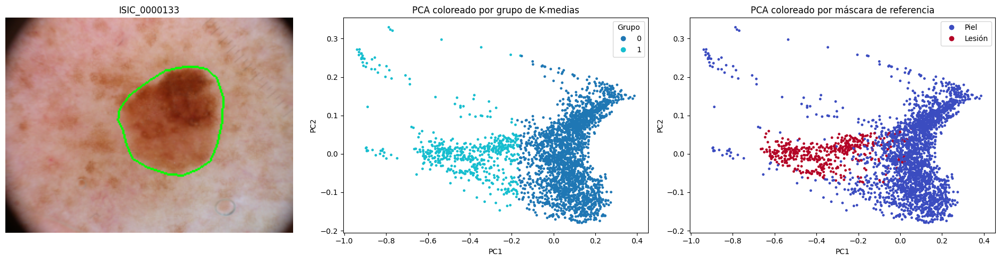

In [24]:
i_bono = "0000133"
X_bono = crear_pipeline(BETA_FINAL, LAM_FINAL).fit_transform(imagenes_ajuste[i_bono])
etiquetas_bono = agrupaciones[(i_bono, BETA_FINAL, LAM_FINAL)]["etiquetas"].ravel()
referencia_bono = referencias[i_bono].ravel()

rng = np.random.RandomState(SEMILLA)
muestra = rng.choice(len(X_bono), TAMANO_MUESTRA, replace=False)
pca = PCA(n_components=2, random_state=SEMILLA).fit(X_bono)
Z = pca.transform(X_bono[muestra])
print("Varianza explicada por las 2 componentes:", pca.explained_variance_ratio_.round(3),
      "total:", round(pca.explained_variance_ratio_.sum(), 3))
print("Cargas de las componentes (filas = componentes, columnas = β·R, β·G, β·B, λ·x, λ·y):")
display(pd.DataFrame(pca.components_, columns=["β·R", "β·G", "β·B", "λ·x", "λ·y"], index=["PC1", "PC2"]).round(3))

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
axes[0].imshow(dibujar_contorno(reducidas[i_bono], referencias[i_bono]))
axes[0].set_title(f"ISIC_{i_bono}")
axes[0].axis("off")
sc = axes[1].scatter(Z[:, 0], Z[:, 1], c=etiquetas_bono[muestra], cmap="tab10", s=6)
axes[1].set_title("PCA coloreado por grupo de K-medias")
axes[1].legend(*sc.legend_elements(), title="Grupo")
sc = axes[2].scatter(Z[:, 0], Z[:, 1], c=referencia_bono[muestra], cmap="coolwarm", s=6)
axes[2].set_title("PCA coloreado por máscara de referencia")
axes[2].legend(sc.legend_elements()[0], ["Piel", "Lesión"])
for ax in axes[1:]:
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
plt.tight_layout()
plt.show()

La PCA conserva el 84.3% de la varianza en dos componentes. La primera componente es casi toda color (cargas de 0.43, 0.59 y 0.68 en R, G y B) y básicamente mide qué tan oscuro es el píxel. La segunda mezcla el rojo con la posición vertical (cargas de -0.42 en R y 0.82 en λ·y).

**Coincidencias.** La lesión aparece como una banda hacia la izquierda de PC1 (píxeles oscuros) y el grupo 1 de K-medias ocupa casi la misma zona. O sea que K-medias está separando lesión de piel principalmente por qué tan oscuro es cada píxel, que es lo que esperábamos.

**Diferencias.** Hay dos. Primero, el grupo 1 tiene una nube de puntos en el extremo izquierdo (PC1 cerca de -0.9) que según la referencia son piel: son las esquinas negras del dermatoscopio, más oscuras incluso que la lesión. Por eso el criterio B necesita quedarse con la región principal. Segundo, cerca del corte entre los dos grupos (PC1 entre -0.2 y 0) hay puntos de lesión asignados a la piel. Son los píxeles del borde de la lesión, más claros, y explican la subsegmentación que vimos en todo el laboratorio. En la proyección se ve que no hay un corte limpio entre lesión y piel en esa zona.

**Limitaciones de la proyección.** PCA es lineal y solo muestra dos de las cinco dimensiones (queda por fuera el 16% de la varianza), entonces dos puntos cercanos en el gráfico pueden estar lejos en el espacio original y la frontera entre grupos que se ve no es exactamente la de K-medias. Además es una muestra de 3000 de los 49152 píxeles, y la forma de las nubes depende de β y λ: con más peso en la posición, la segunda componente sería casi toda posición.

## Bono B - Comparación con mean shift

**Cómo funciona.** Mean shift no parte de un número de grupos fijo. Pone una "ventana" (un kernel) alrededor de cada punto de partida y la mueve repetidamente hacia el promedio de los puntos que caen dentro de ella, o sea, la va subiendo hacia donde los datos están más concentrados. Cada ventana termina en un pico de densidad (una moda), y los puntos que terminan en el mismo pico forman un grupo. Por eso **no hay que fijar K**: el número de grupos sale del número de picos de densidad que tengan los datos.

**El ancho de banda** es el radio de esa ventana y es el hiperparámetro que reemplaza a K. Con un ancho de banda pequeño la ventana ve detalles finos y aparecen muchos picos (muchos grupos). Con uno grande la densidad se suaviza, los picos cercanos se funden y quedan pocos grupos. scikit-learn trae `estimate_bandwidth`, que lo estima como el promedio de la distancia a los vecinos dentro de un cuantil dado.

Mean shift es mucho más costoso que K-medias, entonces lo aplicamos a una imagen de ajuste (ISIC_0000085) reducida a 128 píxeles de lado, con la misma representación de la configuración final. Lo ajustamos sobre una muestra de 3000 píxeles (semilla 42) y después asignamos todos los píxeles al pico más cercano con `predict`. Probamos tres cuantiles para el ancho de banda y comparamos con K-medias (K por silueta) a la misma resolución, usando el mismo criterio de máscara.

In [25]:
i_ms = "0000085"
pipe_ms = crear_pipeline(BETA_FINAL, LAM_FINAL, lado_max=128)
reducida_ms = pipe_ms.named_steps["redimension"].transform(imagenes_ajuste[i_ms])
forma_ms = reducida_ms.shape[:2]
X_ms = pipe_ms.fit_transform(imagenes_ajuste[i_ms])
referencia_ms = preparar_mascara(mascaras_ajuste[i_ms], forma_ms)
muestra_ms = np.random.RandomState(SEMILLA).choice(len(X_ms), TAMANO_MUESTRA, replace=False)

filas, mascaras_ms = [], {}
for cuantil in [0.1, 0.2, 0.3]:
    inicio = time.perf_counter()
    ancho = estimate_bandwidth(X_ms[muestra_ms], quantile=cuantil, random_state=SEMILLA)
    ms = MeanShift(bandwidth=ancho, bin_seeding=True).fit(X_ms[muestra_ms])
    etiquetas = ms.predict(X_ms).reshape(forma_ms)
    segundos = time.perf_counter() - inicio
    estimada = CRITERIOS[CRITERIO_FINAL](reducida_ms, etiquetas)
    mascaras_ms[f"Mean shift (cuantil {cuantil})"] = (etiquetas, estimada)
    filas.append({"Método": f"Mean shift (cuantil {cuantil})", "Ancho de banda": ancho,
                  "Grupos": len(np.unique(etiquetas)), "Dice": dice(referencia_ms, estimada), "Segundos": segundos})

inicio = time.perf_counter()
k_ms, por_k_ms = agrupar(X_ms)
segundos = time.perf_counter() - inicio
etiquetas = por_k_ms[k_ms]["etiquetas"].reshape(forma_ms)
estimada = CRITERIOS[CRITERIO_FINAL](reducida_ms, etiquetas)
mascaras_ms["K-medias (K por silueta)"] = (etiquetas, estimada)
filas.append({"Método": "K-medias (K por silueta)", "Ancho de banda": np.nan, "Grupos": k_ms,
              "Dice": dice(referencia_ms, estimada), "Segundos": segundos})
pd.DataFrame(filas).round(3)

,Método,Ancho de banda,Grupos,Dice,Segundos
0,Mean shift (cuantil 0.1),0.125,6,0.923,0.502
1,Mean shift (cuantil 0.2),0.176,3,0.929,0.561
2,Mean shift (cuantil 0.3),0.210,2,0.940,0.488
3,K-medias (K por silueta),NaN,2,0.910,1.049


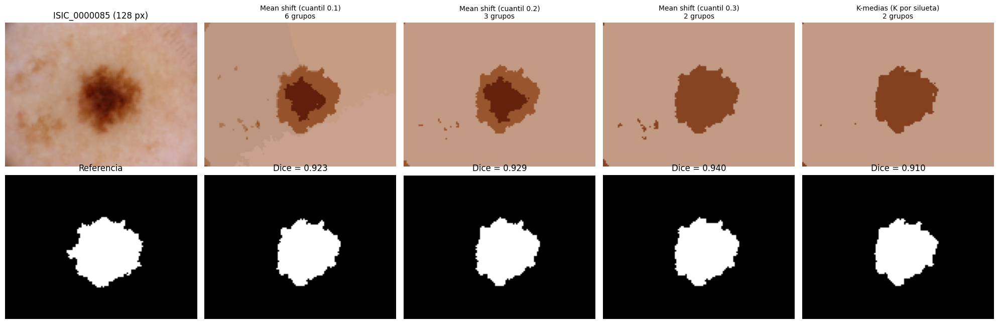

In [26]:
fig, axes = plt.subplots(2, len(mascaras_ms) + 1, figsize=(20, 6.5))
axes[0, 0].imshow(reducida_ms)
axes[0, 0].set_title(f"ISIC_{i_ms} (128 px)")
axes[1, 0].imshow(referencia_ms, cmap="gray")
axes[1, 0].set_title("Referencia")
for col, (nombre, (etiquetas, estimada)) in enumerate(mascaras_ms.items(), start=1):
    axes[0, col].imshow(colorear_grupos(reducida_ms, etiquetas))
    axes[0, col].set_title(f"{nombre}\n{len(np.unique(etiquetas))} grupos", fontsize=10)
    axes[1, col].imshow(estimada, cmap="gray")
    axes[1, col].set_title(f"Dice = {dice(referencia_ms, estimada):.3f}")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

Mean shift funcionó muy bien en esta imagen: con los tres anchos de banda el Dice (0.923 a 0.940) fue mayor que el de K-medias a la misma resolución (0.910). Se ve claramente el efecto del ancho de banda: con el cuantil 0.1 (ancho 0.125) salen 6 grupos y la piel queda partida en zonas, con 0.2 (0.176) quedan 3 y con 0.3 (0.210) solo 2, piel y lesión. Con ventanas más grandes los picos de densidad que están cerca se funden en uno solo. Con 3 y 6 grupos la lesión queda dividida en un centro oscuro y un anillo más claro, y como los dos son más oscuros que la piel, el criterio B los junta. Ese anillo es justamente el borde que K-medias con K = 2 tiende a perder, y por eso el Dice sube.

En tiempo, mean shift tardó cerca de medio segundo y K-medias un segundo, pero la comparación no es del todo justa. Mean shift se ajustó con una muestra de 3000 píxeles y con `bin_seeding`, mientras que K-medias se ajustó con los 12 288 píxeles para 7 valores de K y además calculó la silueta en cada uno. Mean shift con todos los píxeles y sin `bin_seeding` es mucho más lento, porque en cada iteración hay que buscar los vecinos de cada punto dentro de la ventana, y por eso lo tuvimos que correr a 128 píxeles y con muestra. Su ventaja es que no hay que escoger K, pero a cambio hay que escoger el ancho de banda, que es igual de delicado (de 6 a 2 grupos solo moviendo el cuantil). Con una sola imagen no podemos concluir que sea mejor en general.